# Triple-Riding Violation Detection on Indian Roads
### Rider-to-motorcycle association first, everything else second

This notebook detects motorcycles and riders in images and dashcam video, assigns each rider to **exactly one** motorcycle, counts riders per motorcycle, and flags triple riding (>= 3 riders) with temporal confirmation. It is evaluated against the **RideSafe-400** ground-truth rider/motorcycle association IDs.

**What you should know before running**

| Fact | Consequence for this notebook |
|---|---|
| `DeepBug/RideSafe-400` is a *raw file repo* (4 x 2 video zips of ~4.5 GB each + 4 CVAT-XML zips), **not** a tabular `datasets` dataset. `load_dataset(...)` cannot parse it into usable columns. | We read the repo structure with `huggingface_hub`, and use **HTTP range requests** (`remotezip`) to pull *one* video + *one* XML out of a multi-GB zip. Nothing else is downloaded. |
| Ground truth is CVAT-for-video XML: `rider` boxes carry `association_id`, `motorcycle` boxes carry `motor_track_id`; **equal IDs = that rider is on that motorcycle**; `-1` = unlinked. Boxes are annotated every 5th video frame. | Evaluation is done on those annotated frames; the default processing stride is 5 to match. |
| The README advertises 300/50/50 train/val/test splits, but the repo ships **no split file**. | We do not claim an official split. Sampling is seeded random; sampled video IDs are saved with every report. |
| Models used are **pretrained COCO YOLO11 (+ pose)** from Ultralytics. **No fine-tuning is performed** in this notebook. | Reported metrics are for off-the-shelf detectors + our association/tracking logic. |

---
## 1. Design decisions (and what is research vs. my own choice)

**The core problem.** Counting every person inside an expanded motorcycle box fails in dense Indian traffic: pedestrians, riders of the next bike, and people in front/behind all fall inside the box (this is how one bike ends up with 9 "riders"). Fixing this means treating association as an **exclusive assignment problem with geometric plausibility**, not a box-overlap count.

| Component | Choice | Origin / justification |
|---|---|---|
| Motorcycle detector | YOLO11 (COCO class *motorcycle*) | Established (Ultralytics). Strong off-the-shelf recall on two-wheelers. COCO "motorcycle" also covers scooters. |
| Rider detector | YOLO11-**pose** (COCO *person* + 17 keypoints) | **My choice.** One model gives person boxes *and* hip/knee/ankle keypoints. A seated rider has hips over the seat; a pedestrian beside/behind the bike does not. Falls back to box geometry when keypoints are low-confidence or pose is disabled. |
| Why not a 2-class rider/motorcycle detector? | Not used | Goyal et al. train one with curriculum learning because overlapping rider/bike boxes hurt NMS. No public weights exist and training is out of scope; we reduce NMS suppression by running motorcycle and person detection as **separate models** with a permissive NMS IoU (0.7). |
| Association | **Exclusive, soft-geometric scoring -> per-person arg-max with ambiguity rejection -> group-coherence tie-break -> spread/capacity pruning**; then **temporal hysteresis** on person tracks | **My design**, motivated by Goyal et al. (CVPR-W 2022), who show that rectangle-IoU association breaks in crowds (their Fig. 4) and propose a *learned trapezium* "driving-instance" box per motorcycle. Their trapezium regressor and amodal regressor need training data and weights that are not public, so I did **not** reproduce them. I replace the learned region with analytic terms (horizontal containment, centre alignment, hip-in-seat-zone, foot/ground consistency, scale consistency, lower-body overlap) and enforce **one rider -> one motorcycle** by construction. |
| Tracking | **ByteTrack-style** two-stage tracker (own compact implementation: constant-velocity Kalman + Hungarian, high/low-confidence stages) with an added centre-distance term | ByteTrack (Zhang et al., ECCV 2022) is established; this is *not* the reference code. The centre-distance term is my modification, because dashcam ego-motion + a 5-frame stride makes pure IoU fragile for small boxes. No camera-motion compensation (limitation). Own implementation keeps the whole pipeline unit-testable without a GPU. |
| Temporal confirmation | Sliding-window k-of-n rule on per-frame rider counts, plus an occlusion "hold" for rider tracks | **My design.** Single-frame >=3 only yields *Potential*. *Confirmed* needs >=3 frames in the window with >=3 associated riders and adequate association confidence. |
| Confidences | Three **heuristic** scores (detection, association, violation) | **Not calibrated probabilities.** A separate reliability/Brier analysis (and an optional isotonic calibrator) is produced only from evaluation data, and reported under a different name (`calibrated_prob`). |
| Plates | Optional: dedicated YOLO plate detector from the HF Hub + EasyOCR + Indian-format regex | COCO weights have no plate class. The pipeline works if this is unavailable. The plate detector is *not* India-specific (see limitations). |
| Baseline | "Naive expanded-box counting" | Implemented **only** to measure how much the association logic helps, using the same detections. |

**Other literature considered** (not all used): SORT/DeepSORT (Bewley 2016, Wojke 2017), BoT-SORT (Aharon 2022: adds camera-motion compensation + ReID — the natural upgrade for dashcams), OC-SORT (Cao 2023), Hungarian assignment (Kuhn 1955), RT-DETR (Zhao 2023), SAM-based instance masks (would help occlusion but ~10-50x slower), Saumya et al. (Euclidean-distance association — shown by Goyal et al. to be brittle).

---
## 2. How to run
1. *Runtime -> Change runtime type -> GPU (T4)* (CPU works, slower, with smaller models).
2. *Run all*. Cells are ordered; the first cell installs dependencies. If Colab asks to restart after install, restart and run again.
3. Optional: add a Colab secret `HF_TOKEN` (the dataset is public, so this is not required).
4. Everything is written under `CFG.out_dir` (default `/content/triple_riding_outputs`).

Sections: install -> config -> geometry -> association -> tracking -> pipeline -> detectors -> plates -> visualisation -> dataset access -> runners/reports -> evaluation code -> **synthetic tests** -> **GT-oracle association check (no model needed)** -> demo -> full evaluation -> export.

In [ ]:
# --- 0. Install dependencies (Colab only; skipped elsewhere) ---------------------------------
import sys, subprocess, importlib

def _pip(*pkgs):
    cmd = [sys.executable, "-m", "pip", "install", "-q", *pkgs]
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        print("pip failed for", pkgs, "\n", r.stderr[-800:])
    return r.returncode == 0

_REQUIRED = {  # import name -> pip name
    "ultralytics": "ultralytics", "cv2": "opencv-python-headless", "remotezip": "remotezip",
    "huggingface_hub": "huggingface_hub", "scipy": "scipy", "pandas": "pandas",
    "matplotlib": "matplotlib", "sklearn": "scikit-learn", "tqdm": "tqdm",
}
_missing = [pip for mod, pip in _REQUIRED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print("Installing:", _missing)
    _pip(*_missing)
else:
    print("Core dependencies already present.")
# EasyOCR is optional (plate OCR). Failure here must not break the rest of the notebook.
if importlib.util.find_spec("easyocr") is None:
    print("EasyOCR install (optional):", "ok" if _pip("easyocr") else "FAILED (plate OCR will be disabled)")

## 3. Configuration
Every tunable is in one dataclass. Thresholds in the *association* block are **uncalibrated heuristics chosen from geometry reasoning**; the GT-oracle check (section 14) and the optional tuning cell show how they behave on real annotations. Nothing here was tuned on the evaluation videos unless you run the tuning cell with the same seed — see the note in that cell.

In [ ]:
import os, sys, json, time, math, random, shutil, zipfile, pickle, re, warnings, dataclasses, collections, itertools
from dataclasses import dataclass, field, asdict
from pathlib import Path
from typing import Any, Dict, List, Optional, Sequence, Tuple
import numpy as np

warnings.filterwarnings("ignore", category=FutureWarning)
IN_COLAB = "google.colab" in sys.modules

# Status vocabulary (exact strings used in all outputs)
ST_NO   = "No Violation"
ST_POT  = "Potential Violation"
ST_CONF = "Confirmed Triple-Riding Violation"
ST_INS  = "Insufficient Visual Evidence"

@dataclass
class Config:
    # ---- paths -------------------------------------------------------------------------
    out_dir: str = "/content/triple_riding_outputs" if os.path.isdir("/content") else "./triple_riding_outputs"
    # ---- dataset -----------------------------------------------------------------------
    hf_repo: str = "DeepBug/RideSafe-400"
    hf_token: Optional[str] = None          # or env HF_TOKEN / Colab secret HF_TOKEN
    seed: int = 42
    # ---- models ------------------------------------------------------------------------
    device: str = "auto"                    # "auto" | "cuda" | "cpu"
    det_weights: str = "auto"               # auto: yolo11l.pt (GPU) / yolo11n.pt (CPU)
    pose_weights: str = "auto"              # auto: yolo11l-pose.pt (GPU) / yolo11n-pose.pt (CPU)
    use_pose: bool = True
    imgsz: int = 0                          # 0 = auto (1280 GPU / 640 CPU)
    det_floor: float = 0.10                 # detector confidence floor (kept in cache, used for AP)
    nms_iou: float = 0.70                   # permissive: riders on one bike overlap heavily
    # ---- thresholds used for *counting* -----------------------------------------------
    bike_conf: float = 0.30
    person_conf: float = 0.30
    person_dup_iou: float = 0.85            # drop near-identical person boxes
    bike_dup_iou: float = 0.70
    # ---- video -------------------------------------------------------------------------
    frame_stride: int = 5                   # matches RideSafe annotation grid (every 5th frame)
    max_frames: Optional[int] = None        # cap processed frames per video (None = all)
    out_max_width: int = 1280               # annotated output width
    # ---- tracking ----------------------------------------------------------------------
    trk_high: float = 0.45
    trk_low: float = 0.10
    trk_new: float = 0.45
    trk_match: float = 0.30
    trk_buffer: int = 6                     # in *processed* frames
    trk_min_hits: int = 2
    # ---- association (heuristic, uncalibrated) ----------------------------------------
    tau_assign: float = 0.45
    tau_keep: float = 0.35                  # hysteresis: keep an existing assignment above this
    ambiguity_margin: float = 0.08
    max_riders: int = 5
    spread_limit: float = 1.6               # rider centre-x deviation from group median, in bike widths
    kp_conf: float = 0.30
    assoc_weights: Dict[str, float] = field(default_factory=lambda: dict(
        xover=1.0, xcent=1.0, hip_y=1.0, hip_x=0.6, foot=1.0, scale=0.8, overlap=1.0, seated=0.8))
    vote_alpha: float = 0.6                 # EMA decay of per-track association votes
    switch_margin: float = 0.10             # a person track switches bike only if clearly better
    occ_hold: int = 3                       # processed frames a vanished rider track still counts
    # ---- temporal violation logic ------------------------------------------------------
    window: int = 10                        # processed frames in the rolling window
    min_obs: int = 3                        # valid observations needed to say "No Violation"
    confirm_k: int = 3                      # >=k frames with >=3 riders ...
    confirm_ratio: float = 0.40             # ... and >= this fraction of valid frames
    confirm_assoc: float = 0.50             # ... with mean association confidence >= this
    image_confirm: bool = True              # allow strict single-image confirmation
    image_confirm_assoc: float = 0.60
    image_confirm_det: float = 0.50
    min_bike_h_frac: float = 0.025          # bike box height / frame height below this = too small
    border_px: int = 3
    # ---- plates (optional) -------------------------------------------------------------
    use_plates: bool = True
    plate_repo: str = "morsetechlab/yolov11-license-plate-detection"
    plate_file: str = "license-plate-finetune-v1s.pt"
    # ---- evaluation --------------------------------------------------------------------
    eval_iou: float = 0.5
    gt_min_frames: int = 2                  # GT bike is "triple" if >=3 GT riders in >= this many annotated frames

CFG = Config()

def seed_everything(seed: int):
    random.seed(seed); np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
    except Exception:
        pass

def resolve_runtime(cfg: Config) -> Config:
    """Pick device/weights/imgsz. Safe to call repeatedly; never raises if torch is missing."""
    cuda = False
    try:
        import torch
        cuda = torch.cuda.is_available()
    except Exception:
        pass
    if cfg.device == "auto":
        cfg.device = "cuda" if cuda else "cpu"
    if cfg.device == "cuda" and not cuda:
        print("CUDA requested but unavailable -> falling back to CPU")
        cfg.device = "cpu"
    gpu = cfg.device == "cuda"
    if cfg.det_weights == "auto":
        cfg.det_weights = "yolo11l.pt" if gpu else "yolo11n.pt"
    if cfg.pose_weights == "auto":
        cfg.pose_weights = "yolo11l-pose.pt" if gpu else "yolo11n-pose.pt"
    if cfg.imgsz == 0:
        cfg.imgsz = 1280 if gpu else 640
    return cfg

def make_dirs(cfg: Config) -> Dict[str, Path]:
    root = Path(cfg.out_dir)
    d = {k: root / k for k in ["samples", "cache", "annotated_images", "annotated_videos", "evidence",
                               "debug", "reports", "eval", "plates"]}
    for p in d.values():
        p.mkdir(parents=True, exist_ok=True)
    d["root"] = root
    return d

DIRS = make_dirs(CFG)
seed_everything(CFG.seed)
print("Output dir:", CFG.out_dir)

## 4. Geometry helpers

In [ ]:
EPS = 1e-9

def as_boxes(b) -> np.ndarray:
    a = np.asarray(b, dtype=np.float64)
    return a.reshape(-1, 4) if a.size else np.zeros((0, 4), dtype=np.float64)

def box_area(b: np.ndarray) -> np.ndarray:
    b = as_boxes(b)
    return np.clip(b[:, 2] - b[:, 0], 0, None) * np.clip(b[:, 3] - b[:, 1], 0, None)

def iou_matrix(a, b) -> np.ndarray:
    a, b = as_boxes(a), as_boxes(b)
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    union = box_area(a)[:, None] + box_area(b)[None, :] - inter
    return inter / np.maximum(union, EPS)

def ramp_up(x, lo, hi):
    return float(np.clip((x - lo) / max(hi - lo, EPS), 0.0, 1.0))

def ramp_down(x, lo, hi):
    return 1.0 - ramp_up(x, lo, hi)

def trapezoid(x, a, b, c, d):
    """0 below a, rises to 1 at b, flat until c, falls to 0 at d."""
    return min(ramp_up(x, a, b), ramp_down(x, c, d))

def inter_area(a, b) -> float:
    w = min(a[2], b[2]) - max(a[0], b[0]); h = min(a[3], b[3]) - max(a[1], b[1])
    return max(w, 0.0) * max(h, 0.0)

def greedy_nms_dedupe(boxes: np.ndarray, conf: np.ndarray, iou_thr: float) -> np.ndarray:
    """Return indices kept after dropping the lower-confidence box of near-identical pairs."""
    boxes = as_boxes(boxes)
    if len(boxes) == 0:
        return np.zeros(0, dtype=int)
    order = np.argsort(-np.asarray(conf))
    ious = iou_matrix(boxes, boxes)
    keep, dead = [], set()
    for i in order:
        if i in dead:
            continue
        keep.append(int(i))
        for j in order:
            if j != i and j not in dead and ious[i, j] > iou_thr:
                dead.add(int(j))
    return np.array(sorted(keep), dtype=int)

## 5. Rider ↔ motorcycle association  (the part that matters)

**Why not "count people inside an expanded box".** An expanded box is a union of the motorcycle's own riders *and* everything around it. Association has to answer, per person, *"which single motorcycle is this person sitting on, if any?"*

**Stage A – pairwise plausibility score** `S[p, m] in [0, 1]` from eight soft geometric terms (trapezoid membership functions so no single hard threshold flips the decision):

| term | question it asks | rejects |
|---|---|---|
| `xover` | is the person horizontally inside the bike's (slightly widened) extent? | people standing beside the bike |
| `xcent` | is the person's centre aligned with the bike's centre (in bike-widths)? | neighbours' riders |
| `hip_y` | do the **hips** (pose keypoints; else box estimate) lie in the seat zone (around the top of the bike box)? | pedestrians whose hips are far above/below the seat |
| `hip_x` | are the hips over the bike horizontally? | same |
| `foot` | are the feet at a ground depth consistent with the bike's wheels? | people clearly in front of / behind the bike in depth |
| `scale` | is person size consistent with bike size (height & width ratios)? | far-away or very close people |
| `overlap` | does the person's lower body overlap the bike box? | people merely adjacent |
| `seated` | *(pose only)* are the knees near hip height (seated) rather than a full thigh below (standing)? Ignored when keypoints are missing. | pedestrians standing right next to / overlapping the bike |

The score is the **weighted geometric mean** of the terms; a few terms also act as hard gates (`< 0.02` -> score 0). *These terms are my engineering heuristics, in the spirit of Goyal et al.'s "driving-instance region" idea but not a reproduction of it.*

**Stage B – exclusive assignment.** Each person goes to **at most one** bike (arg-max), only if `S >= tau_assign` **and** the runner-up bike is not nearly as good (`ambiguity_margin`). Ambiguous people are *not silently counted*; they get a second chance in Stage C and otherwise are reported as ambiguous.

**Stage C – group coherence tie-break.** An ambiguous person joins the candidate bike whose *already-confident* riders they sit side-by-side with (people on one bike overlap horizontally and share ground depth), if that evidence is clearly one-sided.

**Stage D – pruning.** Riders whose centre deviates too far from their group (`spread_limit`) are dropped; a bike can keep at most `max_riders` (best-scoring).

**Stage E (in the pipeline)** – temporal hysteresis on *person tracks* so an assignment does not flip frame to frame, plus an occlusion hold.

In [ ]:
TERMS = ["xover", "xcent", "hip_y", "hip_x", "foot", "scale", "overlap", "seated"]
GATE_TERMS = ("xover", "foot", "scale", "overlap")
KP_L_SH, KP_R_SH, KP_L_HIP, KP_R_HIP, KP_L_KNEE, KP_R_KNEE = 5, 6, 11, 12, 13, 14

def seated_posture(kpts, kp_conf) -> Optional[float]:
    """Pose cue. thigh_drop / torso_length: ~0.85 for a standing person, ~0.0-0.4 for someone seated on a bike.
    Returns None unless shoulders, hips and knees are all confidently detected."""
    if kpts is None:
        return None
    k = np.asarray(kpts)
    def mid(i, j):
        pts = [k[x, :2] for x in (i, j) if k[x, 2] >= kp_conf]
        return np.mean(pts, axis=0) if pts else None
    sh, hip, kn = mid(KP_L_SH, KP_R_SH), mid(KP_L_HIP, KP_R_HIP), mid(KP_L_KNEE, KP_R_KNEE)
    if sh is None or hip is None or kn is None:
        return None
    torso = hip[1] - sh[1]
    if torso < 4:
        return None
    return float((kn[1] - hip[1]) / torso)

def hip_point(pbox, kpts, kp_conf):
    """Hip centre from pose keypoints if confident, else a box-based estimate. Returns (x, y, from_pose)."""
    if kpts is not None:
        k = np.asarray(kpts)
        pts = [k[i, :2] for i in (KP_L_HIP, KP_R_HIP) if k[i, 2] >= kp_conf]
        if pts:
            p = np.mean(pts, axis=0)
            return float(p[0]), float(p[1]), True
    cx = 0.5 * (pbox[0] + pbox[2]); hp = pbox[3] - pbox[1]
    return float(cx), float(pbox[1] + 0.55 * hp), False

def pair_terms(pbox, mbox, kpts=None, cfg: Config = None) -> Dict[str, float]:
    cfg = cfg or CFG
    px1, py1, px2, py2 = [float(v) for v in pbox]
    mx1, my1, mx2, my2 = [float(v) for v in mbox]
    wp, hp = max(px2 - px1, 1.0), max(py2 - py1, 1.0)
    wm, hm = max(mx2 - mx1, 1.0), max(my2 - my1, 1.0)
    cxp, cxm = 0.5 * (px1 + px2), 0.5 * (mx1 + mx2)
    t = {}
    ex = 0.25 * wm
    ox = max(0.0, min(px2, mx2 + ex) - max(px1, mx1 - ex))
    t["xover"] = ramp_up(ox / wp, 0.20, 0.60)
    d = abs(cxp - cxm) / (0.5 * (wm + wp))
    t["xcent"] = ramp_down(d, 0.40, 0.90)
    hx, hy, from_pose = hip_point(pbox, kpts, cfg.kp_conf)
    v = (hy - my1) / hm
    t["hip_y"] = trapezoid(v, -0.90, -0.35, 0.85, 1.40)
    t["hip_x"] = ramp_down(abs(hx - cxm) / wm, 0.45, 0.95)
    f = (py2 - my2) / hm
    t["foot"] = trapezoid(f, -1.2, -0.6, 0.45, 1.0)
    t["scale"] = min(trapezoid(hp / hm, 0.5, 0.9, 3.2, 5.0), trapezoid(wp / wm, 0.10, 0.25, 2.0, 3.5))
    lower = (px1, py1 + 0.4 * hp, px2, py2)
    mexp = (mx1 - ex, my1 - 0.15 * hm, mx2 + ex, my2 + 0.15 * hm)
    iop = inter_area(lower, mexp) / max((lower[2] - lower[0]) * (lower[3] - lower[1]), EPS)
    t["overlap"] = ramp_up(iop, 0.10, 0.45)
    sp = seated_posture(kpts, cfg.kp_conf)
    t["seated"] = 1.0 if sp is None else max(0.30, ramp_down(sp, 0.45, 0.85))
    t["_hip_from_pose"] = float(from_pose)
    t["_have_seat"] = float(sp is not None)
    return t

def combine_terms(t: Dict[str, float], cfg: Config = None) -> float:
    """Weighted geometric mean of the terms, multiplied by (weakest term)^0.7.
    The geometric mean alone dilutes one clearly failing term across six good ones (a pedestrian touching the bike's
    edge would still score ~0.7); the weakest-term factor stops a single strong violation from being averaged away."""
    cfg = cfg or CFG
    if any(t[g] < 0.02 for g in GATE_TERMS):
        return 0.0
    w = dict(cfg.assoc_weights)
    pose = bool(t.get("_hip_from_pose", 0.0))
    if not pose:                                   # box-estimated hips are less trustworthy
        w["hip_y"] *= 0.6; w["hip_x"] *= 0.6
    w["seated"] = w.get("seated", 0.8) if t.get("_have_seat", 0.0) else 0.0
    tot = sum(w[k] for k in TERMS)
    gm = float(np.exp(sum(w[k] * np.log(max(t[k], 1e-3)) for k in TERMS) / tot))
    weakest = min(t[k] for k in TERMS if w[k] > 0 and (pose or k not in ("hip_y", "hip_x")))
    return gm * float(max(weakest, 0.0) ** 0.7)

@dataclass
class Assign:
    bike: int          # index into the bike array passed to associate()
    score: float
    margin: float      # best - second best score
    source: str = "geometry"   # geometry | group | memory

@dataclass
class Rejected:
    person: int
    bike: Optional[int]        # most plausible bike (for the debug view), or None
    score: float
    reason: str
    terms: Dict[str, float] = field(default_factory=dict)

@dataclass
class AssocResult:
    assign: Dict[int, Assign]
    rejected: List[Rejected]
    ambiguous: Dict[int, List[int]]    # person -> candidate bikes
    S: np.ndarray
    terms: Dict[Tuple[int, int], Dict[str, float]]

def score_matrix(pboxes, mboxes, kpts=None, cfg: Config = None):
    cfg = cfg or CFG
    pboxes, mboxes = as_boxes(pboxes), as_boxes(mboxes)
    P, M = len(pboxes), len(mboxes)
    S = np.zeros((P, M)); terms = {}
    for i in range(P):
        for j in range(M):
            t = pair_terms(pboxes[i], mboxes[j], None if kpts is None else kpts[i], cfg)
            terms[(i, j)] = t
            S[i, j] = combine_terms(t, cfg)
    return S, terms

def _weakest_term(t):
    return min(TERMS, key=lambda k: t[k])

def associate(pboxes, mboxes, kpts=None, cfg: Config = None, S=None, terms=None) -> AssocResult:
    """Exclusive rider->motorcycle assignment. Each person index appears at most once in `assign`."""
    cfg = cfg or CFG
    pboxes, mboxes = as_boxes(pboxes), as_boxes(mboxes)
    P, M = len(pboxes), len(mboxes)
    if S is None:
        S, terms = score_matrix(pboxes, mboxes, kpts, cfg)
    assign: Dict[int, Assign] = {}; rejected: List[Rejected] = []; ambiguous: Dict[int, List[int]] = {}
    if P == 0:
        return AssocResult(assign, rejected, ambiguous, S, terms or {})
    if M == 0:
        rejected = [Rejected(i, None, 0.0, "no_motorcycle_in_frame") for i in range(P)]
        return AssocResult(assign, rejected, ambiguous, S, terms or {})

    # ---- Stage B: per-person arg-max with ambiguity rejection --------------------------
    pending = {}
    for i in range(P):
        order = np.argsort(-S[i]); b = int(order[0]); best = S[i, b]
        second = S[i, order[1]] if M > 1 else 0.0
        if best < cfg.tau_assign:
            reason = "no_bike_nearby" if best < 0.05 else f"low_score(weak:{_weakest_term(terms[(i, b)])})"
            rejected.append(Rejected(i, b if best > 0 else None, float(best), reason, terms[(i, b)]))
        elif second >= cfg.tau_assign and (best - second) < cfg.ambiguity_margin:
            cands = [int(j) for j in order if S[i, j] >= cfg.tau_assign and best - S[i, j] < cfg.ambiguity_margin]
            pending[i] = cands
        else:
            assign[i] = Assign(b, float(best), float(best - second))

    # ---- Stage C: group coherence for ambiguous people ---------------------------------
    def coherence(i, b):
        best = 0.0
        for r, a in assign.items():
            if a.bike != b:
                continue
            q = pboxes[r]
            ox = max(0.0, min(pboxes[i][2], q[2]) - max(pboxes[i][0], q[0]))
            frac = ox / max(min(pboxes[i][2] - pboxes[i][0], q[2] - q[0]), 1.0)
            hq = max(q[3] - q[1], 1.0)
            foot_ok = abs(pboxes[i][3] - q[3]) / hq < 0.45           # shared ground depth
            best = max(best, frac if foot_ok else 0.0)
        return best
    for i, cands in pending.items():
        co = sorted(((coherence(i, b), b) for b in cands), reverse=True)
        if co[0][0] >= 0.40 and (len(co) == 1 or co[0][0] - co[1][0] >= 0.20):
            b = co[0][1]
            assign[i] = Assign(b, float(S[i, b]), float(S[i, b] - max([S[i, c] for c in cands if c != b], default=0.0)), "group")
        else:
            ambiguous[i] = cands
            rejected.append(Rejected(i, cands[0], float(S[i, cands[0]]), "ambiguous_between_bikes", terms[(i, cands[0])]))

    # ---- Stage D: spread outliers + capacity -------------------------------------------
    for b in range(M):
        members = [i for i, a in assign.items() if a.bike == b]
        if not members:
            continue
        wm = max(mboxes[b][2] - mboxes[b][0], 1.0)
        cx = np.array([0.5 * (pboxes[i][0] + pboxes[i][2]) for i in members]); med = float(np.median(cx))
        for i, c in zip(members, cx):
            if abs(c - med) / wm > cfg.spread_limit and len(members) >= 3:
                rejected.append(Rejected(i, b, assign[i].score, "spread_outlier", terms[(i, b)])); del assign[i]
        members = sorted([i for i, a in assign.items() if a.bike == b], key=lambda i: -assign[i].score)
        for i in members[cfg.max_riders:]:
            rejected.append(Rejected(i, b, assign[i].score, "capacity_exceeded", terms[(i, b)])); del assign[i]
    return AssocResult(assign, rejected, ambiguous, S, terms or {})

def naive_expanded_box_counts(pboxes, mboxes, expand_x=0.5, expand_up=1.0, expand_down=0.1) -> Dict[int, List[int]]:
    """BASELINE ONLY: count every person whose centre falls in an expanded rectangle around each bike.
    A person can be counted for several bikes. This is the failure mode the real association avoids."""
    pboxes, mboxes = as_boxes(pboxes), as_boxes(mboxes)
    out = {}
    for j, m in enumerate(mboxes):
        w, h = m[2] - m[0], m[3] - m[1]
        reg = (m[0] - expand_x * w, m[1] - expand_up * h, m[2] + expand_x * w, m[3] + expand_down * h)
        out[j] = [i for i, p in enumerate(pboxes)
                  if reg[0] <= 0.5 * (p[0] + p[2]) <= reg[2] and reg[1] <= 0.5 * (p[1] + p[3]) <= reg[3]]
    return out

## 6. Multi-object tracking (ByteTrack-style, own compact implementation)
Constant-velocity Kalman filter on `(cx, cy, w, h)`, Hungarian matching, and ByteTrack's two-stage scheme (high-confidence detections first, then low-confidence ones to keep existing tracks alive through occlusion). **Own modification:** the similarity is `0.6*IoU + 0.4*centre-closeness`, because a 5-frame stride plus dashcam ego-motion produces small IoUs for small far boxes. Not the reference ByteTrack code; no camera-motion compensation.

In [ ]:
from scipy.optimize import linear_sum_assignment

def xyxy_to_cxcywh(b):
    return np.array([(b[0] + b[2]) / 2, (b[1] + b[3]) / 2, b[2] - b[0], b[3] - b[1]], dtype=np.float64)

def cxcywh_to_xyxy(c):
    return np.array([c[0] - c[2] / 2, c[1] - c[3] / 2, c[0] + c[2] / 2, c[1] + c[3] / 2], dtype=np.float64)

class KalmanBox:
    SP, SV = 1 / 20.0, 1 / 40.0
    def __init__(self, box):
        z = xyxy_to_cxcywh(box); h = max(z[3], 1.0)
        self.x = np.concatenate([z, np.zeros(4)])
        self.P = np.diag(np.square([2 * self.SP * h] * 4 + [10 * self.SV * h] * 4))
        self.F = np.eye(8); self.F[:4, 4:] = np.eye(4)
        self.H = np.eye(4, 8)
    def predict(self):
        h = max(self.x[3], 1.0)
        Q = np.diag(np.square([self.SP * h] * 4 + [self.SV * h] * 4))
        self.x = self.F @ self.x
        self.P = self.F @ self.P @ self.F.T + Q
        self.x[2:4] = np.maximum(self.x[2:4], 1.0)
    def update(self, box):
        z = xyxy_to_cxcywh(box); h = max(self.x[3], 1.0)
        R = np.diag(np.square([self.SP * h] * 4))
        S = self.H @ self.P @ self.H.T + R
        K = self.P @ self.H.T @ np.linalg.inv(S)
        self.x = self.x + K @ (z - self.H @ self.x)
        self.P = (np.eye(8) - K @ self.H) @ self.P
    @property
    def box(self):
        return cxcywh_to_xyxy(self.x)

class Track:
    def __init__(self, box, conf, extra, min_hits):
        self.kf = KalmanBox(box); self.hits = 1; self.tsu = 0
        self.det_box = np.asarray(box, float); self.conf = float(conf); self.extra = extra
        self.id: Optional[int] = None; self.min_hits = min_hits
    @property
    def confirmed(self): return self.hits >= self.min_hits
    @property
    def pred_box(self): return self.kf.box
    def update(self, box, conf, extra):
        self.kf.update(box); self.hits += 1; self.tsu = 0
        self.det_box = np.asarray(box, float); self.conf = float(conf); self.extra = extra

class ByteTrackLite:
    def __init__(self, high=0.45, low=0.10, new=0.45, match=0.30, buffer=6, min_hits=2):
        self.high, self.low, self.new, self.match, self.buffer, self.min_hits = high, low, new, match, buffer, min_hits
        self.tracks: List[Track] = []; self._next = 1

    @staticmethod
    def _sim(tboxes, dboxes):
        iou = iou_matrix(tboxes, dboxes)
        if iou.size == 0:
            return iou
        tc = np.stack([(tboxes[:, 0] + tboxes[:, 2]) / 2, (tboxes[:, 1] + tboxes[:, 3]) / 2], 1)
        dc = np.stack([(dboxes[:, 0] + dboxes[:, 2]) / 2, (dboxes[:, 1] + dboxes[:, 3]) / 2], 1)
        dist = np.linalg.norm(tc[:, None] - dc[None], axis=2)
        scale = np.maximum(tboxes[:, 2] - tboxes[:, 0], tboxes[:, 3] - tboxes[:, 1])[:, None]
        cs = np.clip(1 - dist / (1.5 * np.maximum(scale, 1.0)), 0, 1)
        return 0.6 * iou + 0.4 * cs

    def _match(self, tracks, boxes):
        if not tracks or len(boxes) == 0:
            return [], list(range(len(tracks))), list(range(len(boxes)))
        sim = self._sim(as_boxes([t.pred_box for t in tracks]), as_boxes(boxes))
        r, c = linear_sum_assignment(1.0 - sim)
        pairs = [(i, j) for i, j in zip(r, c) if sim[i, j] >= self.match]
        mi = {i for i, _ in pairs}; mj = {j for _, j in pairs}
        return pairs, [i for i in range(len(tracks)) if i not in mi], [j for j in range(len(boxes)) if j not in mj]

    def update(self, boxes, confs, extras=None) -> List[Track]:
        boxes, confs = as_boxes(boxes), np.asarray(confs, float).reshape(-1)
        extras = extras if extras is not None else [None] * len(boxes)
        for t in self.tracks:
            t.kf.predict(); t.tsu += 1
        hi = [j for j in range(len(boxes)) if confs[j] >= self.high]
        lo = [j for j in range(len(boxes)) if self.low <= confs[j] < self.high]
        # stage 1: all tracks vs high-confidence detections
        pairs, ut, ud = self._match(self.tracks, boxes[hi])
        for i, j in pairs:
            d = hi[j]; self.tracks[i].update(boxes[d], confs[d], extras[d])
        rem = [self.tracks[i] for i in ut]
        # stage 2: tracks that were matched last frame vs low-confidence detections
        cand = [t for t in rem if t.tsu == 1]
        pairs2, ut2, _ = self._match(cand, boxes[lo])
        for i, j in pairs2:
            d = lo[j]; cand[i].update(boxes[d], confs[d], extras[d])
        # new tracks from unmatched high-confidence detections
        for j in ud:
            d = hi[j]
            if confs[d] >= self.new:
                self.tracks.append(Track(boxes[d], confs[d], extras[d], self.min_hits))
        # housekeeping
        alive = []
        for t in self.tracks:
            if t.confirmed and t.id is None:
                t.id = self._next; self._next += 1
            if t.tsu == 0 or (t.confirmed and t.tsu <= self.buffer):
                alive.append(t)
        self.tracks = alive
        return [t for t in self.tracks if t.tsu == 0 and t.confirmed]

    def lost(self) -> List[Track]:
        return [t for t in self.tracks if t.tsu > 0 and t.confirmed]

## 7. Pipeline state: tracking + association + temporal violation logic

**Per processed frame**
1. Filter + de-duplicate detections; update bike and person trackers (images: no tracker, ids = detection order).
2. Run the exclusive association (section 5) on the confidently-detected tracks.
3. **Temporal consistency per person track:** keep an exponential moving average ("votes") of that person's score for each bike. An existing assignment is only changed if the new bike is better by `switch_margin`; an existing assignment survives a weak frame while its score stays above `tau_keep` (hysteresis). Ambiguous frames are resolved by memory when possible.
4. **Occlusion hold:** if a rider track assigned to a visible bike vanishes for <= `occ_hold` frames it still counts (flagged `held`), unless its predicted box almost coincides (IoU > 0.65) with a currently visible rider of the same bike (re-ID duplicate guard; true co-riders overlap ~0.5).
5. Per-bike rolling window -> status (`classify_history`). *Confirmed* needs `confirm_k` frames with >= 3 associated riders among the valid frames of the window, a minimum fraction, and adequate association confidence.

Scores are **heuristic**: `det_conf` = detector confidence; `assoc_conf` = mean(rider score x margin factor); `violation_score` = assoc x det x evidence-count saturation. None is a calibrated probability.

In [ ]:
@dataclass
class FrameDetections:
    bike_xyxy: np.ndarray
    bike_conf: np.ndarray
    person_xyxy: np.ndarray
    person_conf: np.ndarray
    person_kpts: Optional[np.ndarray]     # (P, 17, 3) or None
    frame_hw: Tuple[int, int]
    t_det: float = 0.0                    # detector wall time for this frame (seconds)

    @staticmethod
    def empty(hw=(1080, 1920)):
        return FrameDetections(np.zeros((0, 4)), np.zeros(0), np.zeros((0, 4)), np.zeros(0), None, hw)

@dataclass
class RiderOut:
    pid: int; box: np.ndarray; score: float; margin: float; det_conf: float
    held: bool = False; source: str = "geometry"

@dataclass
class RejectedOut:
    pid: int; box: np.ndarray; det_conf: float; nearest_bike: Optional[int]; score: float; reason: str

@dataclass
class BikeOut:
    bid: int; box: np.ndarray; det_conf: float
    riders: List[RiderOut] = field(default_factory=list)
    n_visible: int = 0; n_held: int = 0; n_ambiguous: int = 0
    assoc_conf: float = 0.0
    status: str = ST_INS; violation_score: float = 0.0; robust_count: int = 0
    frame_ok: bool = True; frame_flags: str = ""
    @property
    def n(self): return self.n_visible + self.n_held

@dataclass
class FrameResult:
    frame_idx: int
    bikes: List[BikeOut]
    rejected: List[RejectedOut]
    ambiguous: List[Tuple[int, np.ndarray, List[int]]]   # (pid, box, candidate bike ids)
    all_persons: List[Tuple[int, np.ndarray, float]] = field(default_factory=list)
    t_track_assoc: float = 0.0

@dataclass
class Obs:
    frame: int; n: int; n_amb: int; assoc_conf: float; det_conf: float; ok: bool

def classify_history(records: Sequence[Obs], cfg: Config, video: bool) -> Tuple[str, float, int]:
    """Pure function: (status, heuristic violation score, robust rider count) from a window of observations."""
    if not records:
        return ST_INS, 0.0, 0
    trip = [r for r in records if r.n >= 3]
    valid = [r for r in records if r.ok or r.n >= 3]
    counts = sorted([r.n for r in valid], reverse=True)
    robust = counts[min(cfg.confirm_k, len(counts)) - 1] if video and counts else (counts[0] if counts else 0)
    amb3 = [r for r in valid if r.n < 3 and r.n + r.n_amb >= 3]
    k = len(trip)
    ma = float(np.mean([r.assoc_conf for r in trip])) if trip else 0.0
    md = float(np.mean([r.det_conf for r in trip])) if trip else 0.0
    if not video:
        r = records[-1]
        if r.n >= 3:
            strict = cfg.image_confirm and r.assoc_conf >= cfg.image_confirm_assoc and r.det_conf >= cfg.image_confirm_det and r.n_amb == 0
            return (ST_CONF if strict else ST_POT), float(r.assoc_conf * r.det_conf), r.n
        if r.n + r.n_amb >= 3:
            return ST_POT, 0.5 * r.assoc_conf * r.det_conf, r.n
        return (ST_NO if r.ok else ST_INS), 0.0, r.n
    vs = ma * md * min(1.0, k / (2.0 * cfg.confirm_k)) if k else 0.0
    if k >= cfg.confirm_k and k / max(len(valid), 1) >= cfg.confirm_ratio and ma >= cfg.confirm_assoc:
        return ST_CONF, float(vs), robust
    if k >= 1 or amb3:
        return ST_POT, float(vs if k else 0.3 * np.mean([r.assoc_conf * r.det_conf for r in amb3])), robust
    if len(valid) >= cfg.min_obs:
        return ST_NO, 0.0, robust
    return ST_INS, 0.0, robust

class _PersonMem:
    __slots__ = ("votes", "assigned", "last_step", "last_box", "last_score", "last_conf")
    def __init__(self):
        self.votes: Dict[int, float] = {}; self.assigned: Optional[int] = None
        self.last_step = -1; self.last_box = None; self.last_score = 0.0; self.last_conf = 0.0

class BikeHistory:
    def __init__(self, window):
        self.win = collections.deque(maxlen=window); self.full: List[Obs] = []
        self.ever_confirmed = False; self.confirm_frame: Optional[int] = None
        self.best_evidence: Optional[dict] = None   # {"score","frame","bike","riders"}
        self.max_n = 0; self.first_frame: Optional[int] = None; self.last_frame: Optional[int] = None
        self.det_confs: List[float] = []

class TripleRidingPipeline:
    def __init__(self, cfg: Config, video: bool = True):
        self.cfg, self.video = cfg, video
        self.bt = ByteTrackLite(cfg.trk_high, cfg.trk_low, cfg.trk_new, cfg.trk_match, cfg.trk_buffer, cfg.trk_min_hits) if video else None
        self.pt = ByteTrackLite(cfg.trk_high, cfg.trk_low, cfg.trk_new, cfg.trk_match, cfg.trk_buffer, cfg.trk_min_hits) if video else None
        self.mem: Dict[int, _PersonMem] = {}
        self.hist: Dict[int, BikeHistory] = {}
        self.step = 0
        self.results: List[FrameResult] = []

    # -- helpers -------------------------------------------------------------------------
    def _filter(self, boxes, conf, extras, dup_iou):
        boxes, conf = as_boxes(boxes), np.asarray(conf, float).reshape(-1)
        if len(boxes) == 0:
            return boxes, conf, []
        keep = greedy_nms_dedupe(boxes, conf, dup_iou)
        return boxes[keep], conf[keep], [extras[i] for i in keep]

    def _views(self, tracker, boxes, conf, extras):
        """Return list of (id, box, conf, extra) for detections of this frame."""
        if tracker is None:
            return [(i + 1, boxes[i], float(conf[i]), extras[i]) for i in range(len(boxes))]
        return [(t.id, t.det_box, t.conf, t.extra) for t in tracker.update(boxes, conf, extras)]

    # -- main ----------------------------------------------------------------------------
    def process(self, frame_idx: int, det: FrameDetections) -> FrameResult:
        cfg = self.cfg; t0 = time.perf_counter(); self.step += 1
        H, W = det.frame_hw
        kp = det.person_kpts
        pextra = [None if kp is None else kp[i] for i in range(len(det.person_xyxy))]
        mb, mc, _ = self._filter(det.bike_xyxy, det.bike_conf, [None] * len(det.bike_conf), cfg.bike_dup_iou)
        pb, pc, pe = self._filter(det.person_xyxy, det.person_conf, pextra, cfg.person_dup_iou)
        bviews = self._views(self.bt, mb, mc, [None] * len(mb))
        pviews = self._views(self.pt, pb, pc, pe)
        bviews = [v for v in bviews if v[2] >= cfg.bike_conf]
        pviews = [v for v in pviews if v[2] >= cfg.person_conf]

        bids = [v[0] for v in bviews]; bboxes = as_boxes([v[1] for v in bviews])
        pids = [v[0] for v in pviews]; pboxes = as_boxes([v[1] for v in pviews])
        pconfs = [v[2] for v in pviews]
        pk = None if kp is None else [v[3] for v in pviews]
        if pk is not None and any(x is None for x in pk):
            pk = None

        ar = associate(pboxes, bboxes, pk, cfg)
        S = ar.S
        bike_index = {bid: j for j, bid in enumerate(bids)}

        # ---- temporal consistency of person->bike assignment ---------------------------
        final: Dict[int, Tuple[int, float, float, str]] = {}      # person row -> (bike col, score, margin, src)
        rej_reason = {r.person: r for r in ar.rejected}
        for i, pid in enumerate(pids):
            mem = self.mem.setdefault(pid, _PersonMem())
            if self.video:
                for bid in list(mem.votes):
                    mem.votes[bid] *= cfg.vote_alpha
                for j, bid in enumerate(bids):
                    mem.votes[bid] = mem.votes.get(bid, 0.0) + (1 - cfg.vote_alpha) * S[i, j]
                mem.votes = {b: v for b, v in mem.votes.items() if v > 0.02}
            prev = mem.assigned
            prev_col = bike_index.get(prev) if prev is not None else None
            cur = ar.assign.get(i)
            choice = None
            if cur is not None:
                choice = (cur.bike, cur.score, cur.margin, cur.source)
                if self.video and prev_col is not None and prev_col != cur.bike and S[i, prev_col] >= cfg.tau_keep \
                        and mem.votes.get(bids[cur.bike], 0) < mem.votes.get(prev, 0) + cfg.switch_margin:
                    choice = (prev_col, float(S[i, prev_col]), 0.0, "memory")
            elif self.video and prev_col is not None and S[i, prev_col] >= cfg.tau_keep:
                choice = (prev_col, float(S[i, prev_col]), 0.0, "memory")
            if choice is not None:
                final[i] = choice
                mem.assigned = bids[choice[0]]
            else:
                mem.assigned = None if (prev is None or prev in bike_index) else prev   # keep memory if the bike is not visible
            mem.last_step, mem.last_box, mem.last_conf = self.step, pboxes[i].copy(), pconfs[i]
            mem.last_score = choice[1] if choice else 0.0

        # ---- build per-bike outputs ----------------------------------------------------
        bikes: List[BikeOut] = []
        amb_by_bike = collections.Counter()
        for i, cands in ar.ambiguous.items():
            if i in final:                         # resolved by memory
                continue
            for c in cands:
                amb_by_bike[c] += 1
        for j, (bid, bbox, bconf, _) in enumerate(bviews):
            riders = []
            for i, (col, sc, mg, src) in final.items():
                if col == j:
                    mgf = 0.5 + 0.5 * float(np.clip(mg / 0.25, 0, 1)) if src != "memory" else 0.75
                    riders.append(RiderOut(pids[i], pboxes[i], float(sc), float(mg), pconfs[i], False, src))
                    riders[-1].score = float(sc) * mgf
            bo = BikeOut(bid, np.asarray(bbox, float), bconf, riders, n_visible=len(riders), n_ambiguous=int(amb_by_bike[j]))
            bikes.append(bo)

        # occlusion hold (video only)
        if self.video:
            lost_boxes = {t.id: t.pred_box for t in self.pt.lost()}
            by_bid = {b.bid: b for b in bikes}
            for pid, mem in self.mem.items():
                if mem.assigned in by_bid and 0 < self.step - mem.last_step <= cfg.occ_hold and pid in lost_boxes:
                    b = by_bid[mem.assigned]; pb_ = lost_boxes[pid]
                    wm = max(b.box[2] - b.box[0], 1.0)
                    cx = 0.5 * (pb_[0] + pb_[2])
                    near = b.box[0] - 0.75 * wm <= cx <= b.box[2] + 0.75 * wm
                    dup = any(iou_matrix(pb_, r.box)[0, 0] > 0.65 for r in b.riders if not r.held)
                    if near and not dup and len(b.riders) < cfg.max_riders:
                        b.riders.append(RiderOut(pid, np.asarray(pb_, float), mem.last_score * 0.6, 0.0, mem.last_conf, True, "hold"))
                        b.n_held += 1
            for pid in [p for p, m in self.mem.items() if self.step - m.last_step > 4 * cfg.trk_buffer]:
                del self.mem[pid]

        # per-bike confidence, frame quality, temporal status
        min_h = cfg.min_bike_h_frac * H
        for b in bikes:
            b.assoc_conf = float(np.mean([r.score for r in b.riders])) if b.riders else 0.0
            h = b.box[3] - b.box[1]
            flags = []
            if h < min_h: flags.append("small")
            if b.box[0] <= cfg.border_px or b.box[2] >= W - cfg.border_px or b.box[3] >= H - cfg.border_px: flags.append("truncated")
            b.frame_ok = not flags; b.frame_flags = ",".join(flags)
            hs = self.hist.setdefault(b.bid, BikeHistory(cfg.window))
            ob = Obs(frame_idx, b.n, b.n_ambiguous, b.assoc_conf, b.det_conf, b.frame_ok)
            hs.win.append(ob); hs.full.append(ob); hs.det_confs.append(b.det_conf)
            hs.first_frame = frame_idx if hs.first_frame is None else hs.first_frame; hs.last_frame = frame_idx
            hs.max_n = max(hs.max_n, b.n)
            st, vs, rc = classify_history(list(hs.win), cfg, self.video)
            if hs.ever_confirmed and st != ST_CONF:
                st = ST_CONF                       # confirmed violations stay confirmed for this vehicle
            if st == ST_CONF and not hs.ever_confirmed:
                hs.ever_confirmed, hs.confirm_frame = True, frame_idx
            b.status, b.violation_score, b.robust_count = st, vs, rc
            if b.n >= 3:
                ev = b.assoc_conf * b.det_conf
                if hs.best_evidence is None or ev > hs.best_evidence["score"]:
                    hs.best_evidence = dict(score=ev, frame=frame_idx, bike=b.box.copy(), riders=[r.box.copy() for r in b.riders])

        rejected = []
        for r in ar.rejected:
            if r.person in final:
                continue
            nb = bids[r.bike] if r.bike is not None else None
            rejected.append(RejectedOut(pids[r.person], pboxes[r.person], pconfs[r.person], nb, r.score, r.reason))
        ambiguous = [(pids[i], pboxes[i], [bids[c] for c in cands]) for i, cands in ar.ambiguous.items() if i not in final]
        assigned_pids = {pids[i] for i in final}
        all_persons = [(pids[i], pboxes[i], pconfs[i]) for i in range(len(pids))]
        res = FrameResult(frame_idx, bikes, rejected, ambiguous, all_persons, time.perf_counter() - t0)
        self.results.append(res)
        return res

    def vehicle_summary(self) -> List[dict]:
        rows = []
        for bid, hs in sorted(self.hist.items()):
            st_full, vs_full, rc_full = classify_history(hs.full, self.cfg, self.video)
            st = ST_CONF if hs.ever_confirmed else (ST_POT if st_full == ST_CONF else st_full)
            trip = [o for o in hs.full if o.n >= 3]
            rows.append(dict(
                vehicle_id=bid, first_frame=hs.first_frame, last_frame=hs.last_frame, n_observations=len(hs.full),
                robust_rider_count=rc_full, max_rider_count_any_frame=hs.max_n, frames_with_3plus=len(trip),
                final_status=st, confirmed_at_frame=hs.confirm_frame,
                det_conf_mean=float(np.mean(hs.det_confs)) if hs.det_confs else 0.0,
                assoc_conf_mean_triple_frames=float(np.mean([o.assoc_conf for o in trip])) if trip else 0.0,
                violation_score_heuristic=float(vs_full)))
        return rows

## 8. Detectors (Ultralytics YOLO11) and a detection cache
* **Motorcycles:** YOLO11 detection model, COCO class 3.
* **People/riders:** YOLO11-**pose** (COCO class 0 + 17 keypoints). If the pose weights cannot be loaded the code falls back to the detection model's person class (no keypoints; the association then uses box-based hip estimates).
* Both run at a low confidence floor (`det_floor`) with permissive NMS (`nms_iou=0.7`, because riders on one bike overlap heavily); the *counting* thresholds are applied later in the pipeline. Raw detections are **cached** per video, so association/tracking parameters can be re-evaluated without re-running the detectors, and so AP can be computed.
* Weights are pretrained COCO checkpoints downloaded by Ultralytics. **Nothing is fine-tuned here.** (Ultralytics is AGPL-3.0 — check licence terms for commercial use.)

In [ ]:
COCO_PERSON, COCO_MOTORCYCLE = 0, 3

class YoloDetector:
    def __init__(self, cfg: Config):
        resolve_runtime(cfg); self.cfg = cfg
        try:
            from ultralytics import YOLO
        except Exception as e:
            raise RuntimeError("ultralytics is not installed; run the install cell. " + str(e))
        self.det = YOLO(cfg.det_weights)
        self.pose = None
        if cfg.use_pose:
            try:
                self.pose = YOLO(cfg.pose_weights)
            except Exception as e:
                print(f"Pose model unavailable ({type(e).__name__}); falling back to person boxes without keypoints.")
        print(f"Detector ready | device={cfg.device} det={cfg.det_weights} pose={cfg.pose_weights if self.pose else None} imgsz={cfg.imgsz}")

    def _predict(self, model, frame, classes=None):
        # `half` is intentionally not passed: Ultralytics has renamed/deprecated it across versions (fp32 is fast enough on a T4).
        kw = dict(imgsz=self.cfg.imgsz, conf=self.cfg.det_floor, iou=self.cfg.nms_iou, device=self.cfg.device, verbose=False)
        if classes is not None:
            kw["classes"] = classes
        return model.predict(frame, **kw)[0]

    def detect(self, frame_bgr: np.ndarray) -> FrameDetections:
        t0 = time.perf_counter(); out = self._detect(frame_bgr); out.t_det = time.perf_counter() - t0
        return out

    def _detect(self, frame_bgr: np.ndarray) -> FrameDetections:
        h, w = frame_bgr.shape[:2]
        want = [COCO_MOTORCYCLE] if self.pose is not None else [COCO_MOTORCYCLE, COCO_PERSON]
        r = self._predict(self.det, frame_bgr, want)
        xyxy = r.boxes.xyxy.cpu().numpy().astype(float) if len(r.boxes) else np.zeros((0, 4))
        conf = r.boxes.conf.cpu().numpy().astype(float) if len(r.boxes) else np.zeros(0)
        cls = r.boxes.cls.cpu().numpy().astype(int) if len(r.boxes) else np.zeros(0, int)
        bike_m = cls == COCO_MOTORCYCLE
        bikes, bconf = xyxy[bike_m], conf[bike_m]
        if self.pose is None:
            pm = cls == COCO_PERSON
            return FrameDetections(bikes, bconf, xyxy[pm], conf[pm], None, (h, w))
        rp = self._predict(self.pose, frame_bgr)
        if len(rp.boxes) == 0:
            return FrameDetections(bikes, bconf, np.zeros((0, 4)), np.zeros(0), None, (h, w))
        pxy = rp.boxes.xyxy.cpu().numpy().astype(float); pcf = rp.boxes.conf.cpu().numpy().astype(float)
        kp = rp.keypoints.data.cpu().numpy().astype(float) if rp.keypoints is not None and tuple(rp.keypoints.data.shape[1:]) == (17, 3) else None
        return FrameDetections(bikes, bconf, pxy, pcf, kp, (h, w))

def cache_path(stem: str, cfg: Config) -> Path:
    tag = f"{Path(cfg.det_weights).stem}_{Path(cfg.pose_weights).stem if cfg.use_pose else 'nopose'}_{cfg.imgsz}_s{cfg.frame_stride}"
    return DIRS["cache"] / f"{stem}__{tag}.pkl"

_DET_FIELDS = ("bike_xyxy", "bike_conf", "person_xyxy", "person_conf", "person_kpts", "frame_hw", "t_det")

def load_cache(stem, cfg) -> Dict[int, FrameDetections]:
    """Cache holds plain dicts/arrays (not class instances), so it survives re-running the class-definition cell."""
    p = cache_path(stem, cfg)
    if p.exists():
        try:
            with open(p, "rb") as f:
                raw = pickle.load(f)
            return {int(k): FrameDetections(**v) for k, v in raw.items()}
        except Exception as e:
            print("cache unreadable, recomputing:", type(e).__name__, e)
    return {}

def save_cache(stem, cfg, dets: Dict[int, FrameDetections]):
    raw = {int(k): {n: getattr(v, n) for n in _DET_FIELDS} for k, v in dets.items()}
    with open(cache_path(stem, cfg), "wb") as f:
        pickle.dump(raw, f)

## 9. Optional: number-plate detection + OCR
**COCO YOLO weights have no licence-plate class**, so plates need a dedicated detector. By default we try the community model `morsetechlab/yolov11-license-plate-detection` (AGPL-3.0, trained on general plate data, **not India-specific**). OCR is EasyOCR with an alphanumeric allow-list; the text is then checked against the Indian registration format (`SS NN [A-Z]{0,3} NNNN`, e.g. `KA01AB1234`) with position-aware O/0, I/1, B/8, S/5 corrections. If the detector or OCR cannot be loaded, `PlateReader.available` is `False` and every other part of the notebook is unaffected.

Plates are only attempted on **evidence crops of flagged vehicles**, never on every frame. On dashcam footage the plate is often too small/blurred to read; the result then reports `plate_text=None` rather than a guess. Plate output is *not* evaluated against ground truth here.

In [ ]:
_STATE_CODES = {"AN","AP","AR","AS","BR","CH","CG","DD","DL","DN","GA","GJ","HR","HP","JH","JK","KA","KL","LA","LD","MH","ML","MN","MP","MZ","NL","OD","OR","PB","PY","RJ","SK","TN","TR","TS","UK","UP","WB"}
_TO_DIGIT = {"O": "0", "Q": "0", "D": "0", "I": "1", "L": "1", "Z": "2", "S": "5", "B": "8", "G": "6", "T": "7"}
_TO_ALPHA = {"0": "O", "1": "I", "5": "S", "8": "B", "2": "Z", "6": "G"}
_PLATE_RE = re.compile(r"^([A-Z]{2})(\d{1,2})([A-Z]{0,3})(\d{4})$")

def normalize_indian_plate(raw: str) -> Tuple[str, bool]:
    """Return (cleaned text, matches Indian format with a valid state code).
    Position-aware fixes: state letters (0-1), district digit(s) (2-3), series letters, 4 trailing digits.
    The 4th character may be a digit (2-digit district) or a series letter, so both readings are tried."""
    s = re.sub(r"[^A-Za-z0-9]", "", raw or "").upper()
    if len(s) < 8 or len(s) > 11:
        return s, False
    base = list(s)
    for i in (0, 1):
        base[i] = _TO_ALPHA.get(base[i], base[i])
    for i in range(len(base) - 4, len(base)):
        base[i] = _TO_DIGIT.get(base[i], base[i])
    base[2] = _TO_DIGIT.get(base[2], base[2])
    variants = []
    for fix3 in (False, True):
        v = base[:]
        if fix3:
            v[3] = _TO_DIGIT.get(v[3], v[3])
        variants.append("".join(v))
    for v in variants:
        m = _PLATE_RE.match(v)
        if m and m.group(1) in _STATE_CODES:
            return v, True
    return variants[0], False

class PlateReader:
    def __init__(self, cfg: Config):
        self.cfg, self.det, self.ocr, self.available, self.why = cfg, None, None, False, ""
        if not cfg.use_plates:
            self.why = "disabled in CFG"; return
        try:
            from huggingface_hub import hf_hub_download
            from ultralytics import YOLO
            self.det = YOLO(hf_hub_download(cfg.plate_repo, cfg.plate_file))
        except Exception as e:
            self.why = f"plate detector unavailable ({type(e).__name__}: {str(e)[:120]})"; return
        try:
            import easyocr
            self.ocr = easyocr.Reader(["en"], gpu=(cfg.device == "cuda"), verbose=False)
        except Exception as e:
            self.why = f"OCR unavailable ({type(e).__name__}); plates will be detected but not read"
        self.available = True

    def read(self, crop_bgr: np.ndarray) -> dict:
        res = dict(plate_text=None, plate_valid_format=False, plate_det_conf=None, plate_ocr_conf=None, plate_box=None)
        if not self.available or crop_bgr is None or crop_bgr.size == 0:
            return res
        try:
            r = self.det.predict(crop_bgr, imgsz=640, conf=0.25, device=self.cfg.device, verbose=False)[0]
            if len(r.boxes) == 0:
                return res
            j = int(r.boxes.conf.argmax()); x1, y1, x2, y2 = [int(v) for v in r.boxes.xyxy[j].tolist()]
            res.update(plate_det_conf=float(r.boxes.conf[j]), plate_box=[x1, y1, x2, y2])
            if self.ocr is None:
                return res
            pl = crop_bgr[max(y1, 0):y2, max(x1, 0):x2]
            if pl.size == 0:
                return res
            import cv2
            pl = cv2.resize(pl, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC)
            outs = self.ocr.readtext(pl, allowlist="ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789", detail=1, paragraph=False)
            if not outs:
                return res
            outs = sorted(outs, key=lambda o: (round(o[0][0][1] / max(pl.shape[0] / 2, 1)), o[0][0][0]))   # rows, then x
            raw = "".join(o[1] for o in outs); conf = float(np.mean([o[2] for o in outs]))
            text, valid = normalize_indian_plate(raw)
            res.update(plate_text=text or None, plate_valid_format=valid, plate_ocr_conf=conf)
        except Exception as e:
            res["plate_error"] = f"{type(e).__name__}: {str(e)[:100]}"
        return res

## 11. Visualisation
Colour code: **green** = No Violation, **orange** = Potential, **red** = Confirmed triple-riding, **grey** = Insufficient evidence. Each motorcycle shows `#ID  riders:N  STATUS` and, underneath, `det / assoc / viol` — three **heuristic** scores (not probabilities). The translucent polygon is the **association region** (convex hull of the bike and its accepted riders); cyan riders are visible, dashed magenta riders are *held through occlusion*.

**Debug view** (`debug=True`): accepted associations are drawn as green lines with their score; **rejected people are red dashed boxes with the rejection reason** (`low_score(weak:<term>)`, `no_bike_nearby`, `ambiguous_between_bikes`, `spread_outlier`, `capacity_exceeded`); ambiguous people are yellow. Use it first when a rider count looks wrong.

In [ ]:
import cv2
STATUS_COLOR = {ST_NO: (60, 180, 60), ST_POT: (0, 165, 255), ST_CONF: (40, 40, 230), ST_INS: (150, 150, 150)}
STATUS_SHORT = {ST_NO: "OK", ST_POT: "POTENTIAL", ST_CONF: "TRIPLE-RIDING", ST_INS: "INSUFFICIENT"}

def _label(img, text, org, color, scale=0.5, thick=1):
    (w, h), bl = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, scale, thick)
    x, y = int(org[0]), int(org[1])
    y = max(y, h + 4)
    cv2.rectangle(img, (x, y - h - 4), (x + w + 4, y + bl - 2), color, -1)
    cv2.putText(img, text, (x + 2, y - 3), cv2.FONT_HERSHEY_SIMPLEX, scale, (255, 255, 255), thick, cv2.LINE_AA)

def _dashed_rect(img, p1, p2, color, thick=1, dash=6):
    (x1, y1), (x2, y2) = p1, p2
    for (a, b) in (((x1, y1), (x2, y1)), ((x2, y1), (x2, y2)), ((x2, y2), (x1, y2)), ((x1, y2), (x1, y1))):
        n = int(max(abs(b[0] - a[0]), abs(b[1] - a[1])) // dash)
        for k in range(0, n, 2):
            s = (int(a[0] + (b[0] - a[0]) * k / max(n, 1)), int(a[1] + (b[1] - a[1]) * k / max(n, 1)))
            e = (int(a[0] + (b[0] - a[0]) * (k + 1) / max(n, 1)), int(a[1] + (b[1] - a[1]) * (k + 1) / max(n, 1)))
            cv2.line(img, s, e, color, thick)

def draw_result(frame_bgr: np.ndarray, res: FrameResult, cfg: Config, scale: float = 1.0, debug: bool = False,
                title: str = "") -> np.ndarray:
    img = cv2.resize(frame_bgr, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA) if scale != 1.0 else frame_bgr.copy()
    S = lambda b: [int(round(v * scale)) for v in b]
    th = max(1, int(round(2 * max(img.shape[:2]) / 1280)))
    fs = max(0.4, 0.5 * max(img.shape[:2]) / 1280)
    overlay = img.copy()
    for b in res.bikes:                                         # association regions
        pts = [[b.box[0], b.box[1]], [b.box[2], b.box[1]], [b.box[2], b.box[3]], [b.box[0], b.box[3]]]
        for r in b.riders:
            pts += [[r.box[0], r.box[1]], [r.box[2], r.box[1]], [r.box[0], r.box[3]], [r.box[2], r.box[3]]]
        hull = cv2.convexHull((np.array(pts) * scale).astype(np.int32))
        cv2.fillPoly(overlay, [hull], STATUS_COLOR[b.status])
    img = cv2.addWeighted(overlay, 0.18, img, 0.82, 0)
    for b in res.bikes:
        col = STATUS_COLOR[b.status]; x1, y1, x2, y2 = S(b.box)
        bc = ((x1 + x2) // 2, (y1 + y2) // 2)
        for r in b.riders:
            rx1, ry1, rx2, ry2 = S(r.box)
            if r.held:
                _dashed_rect(img, (rx1, ry1), (rx2, ry2), (255, 0, 255), max(1, th - 1))
            else:
                cv2.rectangle(img, (rx1, ry1), (rx2, ry2), (255, 200, 0), max(1, th - 1))
            if debug:
                cv2.line(img, ((rx1 + rx2) // 2, (ry1 + ry2) // 2), bc, (0, 220, 0), 1, cv2.LINE_AA)
                _label(img, f"{r.score:.2f}{'*' if r.held else ''}", (rx1, ry2 + 14), (0, 130, 0), fs * 0.8)
        cv2.rectangle(img, (x1, y1), (x2, y2), col, th + 1)
        _label(img, f"#{b.bid} riders:{b.n} {STATUS_SHORT[b.status]}", (x1, y1 - 2), col, fs)
        _label(img, f"det {b.det_conf:.2f} assoc {b.assoc_conf:.2f} viol {b.violation_score:.2f}", (x1, y2 + 16), (70, 70, 70), fs * 0.8)
    if debug:
        for rj in res.rejected:
            x1, y1, x2, y2 = S(rj.box)
            _dashed_rect(img, (x1, y1), (x2, y2), (0, 0, 255), th)
            _label(img, f"REJ {rj.reason} {rj.score:.2f}", (x1, y1 - 2), (0, 0, 200), fs * 0.75)
        for pid, box, cands in res.ambiguous:
            x1, y1, x2, y2 = S(box); _dashed_rect(img, (x1, y1), (x2, y2), (0, 220, 255), th)
            _label(img, f"AMBIGUOUS {cands}", (x1, y2 + 14), (0, 150, 190), fs * 0.75)
    head = (title + "  " if title else "") + f"frame {res.frame_idx}  bikes {len(res.bikes)}"
    _label(img, head, (4, 22), (40, 40, 40), fs)
    return img

def crop_region(frame, bike_box, rider_boxes, pad=0.5):
    pts = np.array([bike_box] + list(rider_boxes))
    x1, y1, x2, y2 = pts[:, 0].min(), pts[:, 1].min(), pts[:, 2].max(), pts[:, 3].max()
    w, h = x2 - x1, y2 - y1
    H, W = frame.shape[:2]
    a, b = int(max(0, x1 - pad * w)), int(max(0, y1 - pad * h)); c, d = int(min(W, x2 + pad * w)), int(min(H, y2 + pad * h))
    return frame[b:d, a:c].copy(), (a, b)

def render_evidence(crop, offset, bike_box, rider_boxes, label, scale_to=640):
    img = crop.copy(); ox, oy = offset
    cv2.rectangle(img, (int(bike_box[0] - ox), int(bike_box[1] - oy)), (int(bike_box[2] - ox), int(bike_box[3] - oy)), (40, 40, 230), 2)
    for r in rider_boxes:
        cv2.rectangle(img, (int(r[0] - ox), int(r[1] - oy)), (int(r[2] - ox), int(r[3] - oy)), (255, 200, 0), 2)
    s = scale_to / max(img.shape[:2]); img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_CUBIC if s > 1 else cv2.INTER_AREA)
    _label(img, label, (4, 20), (40, 40, 230), 0.5)
    return img

def show_bgr(img, title="", figsize=(12, 7)):
    import matplotlib.pyplot as plt
    plt.figure(figsize=figsize); plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.axis("off")
    if title: plt.title(title)
    plt.show()

def show_video(path, width=720):
    """Inline playback in Colab/Jupyter (base64; skipped above 40 MB)."""
    try:
        from IPython.display import HTML, display
    except ImportError:
        print("IPython not available; video saved at", path); return
    import base64
    p = Path(path)
    if not p.exists() or p.stat().st_size > 40 * 2**20:
        print("Video not embedded (missing or >40 MB):", p); return
    b64 = base64.b64encode(p.read_bytes()).decode()
    display(HTML(f'<video width={width} controls><source src="data:video/mp4;base64,{b64}" type="video/mp4"></video>'))

## 10. Dataset access: RideSafe-400
**Inspected structure (verified against the Hub API, not assumed):** the repo contains `videosetN_videos_part{1,2}.zip` (~4.5 GB each, ~50 `.mp4` each), `videosetN_xml_annots_with_rider_motor_poly.zip` (~100 CVAT-for-video XMLs, 130-210 MB per zip) and small `vids_names_*.txt` / `constructor_cvat_*.txt` files. There are no parquet/arrow files, so `datasets.load_dataset("DeepBug/RideSafe-400")` has nothing to build a table from. Instead we:
1. read each zip's *central directory* through HTTP range requests (a few KB) to build a `stem -> (zip, member)` index,
2. extract **only the one XML and one MP4** we need (~100 MB per video) with further range requests.

XML facts used (from the repo README and from parsing a real file): `rider` boxes have `association_id`; `motorcycle` boxes have `motor_track_id`; equal values => same vehicle; `-1` => unlinked. Frame numbers are original video-frame indices on a grid given by `frame_filter` (**step 5 in most files, but step 1 in some** — checked on real files) and cover a 300-frame job window `[start_frame, stop_frame]`, which may be shorter than the video. `outside=1` boxes are ignored.

In [ ]:
from tqdm.auto import tqdm
import xml.etree.ElementTree as ET

def hf_authenticate(cfg: Config) -> Optional[str]:
    """Resolve an HF token from CFG / env / Colab secret and log in. The dataset is public, so no token is fine."""
    token = cfg.hf_token or os.environ.get("HF_TOKEN") or os.environ.get("HUGGING_FACE_HUB_TOKEN")
    if not token and IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("HF_TOKEN")
        except Exception:
            token = None
    if token:
        try:
            from huggingface_hub import login
            login(token=token, add_to_git_credential=False)
            print("Hugging Face: authenticated.")
        except Exception as e:
            print(f"Hugging Face login failed ({type(e).__name__}); continuing anonymously.")
            token = None
    else:
        print("Hugging Face: no token found; using anonymous access (dataset is public).")
    return token

def _hf_url(cfg: Config, filename: str) -> str:
    return f"https://huggingface.co/datasets/{cfg.hf_repo}/resolve/main/{filename}"

def _open_remote_zip(cfg: Config, filename: str, token: Optional[str]):
    from remotezip import RemoteZip
    headers = {"Authorization": f"Bearer {token}"} if token else {}
    last = None
    for attempt in range(3):
        try:
            return RemoteZip(_hf_url(cfg, filename), headers=headers)
        except Exception as e:
            last = e; time.sleep(1.5 * (attempt + 1))
    raise RuntimeError(f"Could not open remote zip {filename}: {last}")

def build_index(cfg: Config, token: Optional[str] = None, refresh: bool = False) -> Dict[str, dict]:
    """stem -> dict(videoset, xml_zip, xml_member, video_zip, video_member). Cached on disk (12 tiny range requests)."""
    cache = DIRS["cache"] / "ridesafe_index.json"
    if cache.exists() and not refresh:
        try:
            return json.loads(cache.read_text())
        except Exception:
            pass
    from huggingface_hub import HfApi
    try:
        files = [f for f in HfApi().list_repo_files(cfg.hf_repo, repo_type="dataset", token=token)]
    except Exception as e:
        raise RuntimeError(f"Cannot list dataset repo '{cfg.hf_repo}': {type(e).__name__}: {e}. "
                           "Check internet access / HF token / repo name.")
    index: Dict[str, dict] = {}
    xml_zips = sorted(f for f in files if f.endswith("_xml_annots_with_rider_motor_poly.zip"))
    vid_zips = sorted(f for f in files if "_videos_part" in f and f.endswith(".zip"))
    print(f"Repo has {len(files)} files: {len(xml_zips)} xml zips, {len(vid_zips)} video zips (no parquet/arrow -> not load_dataset-able)")
    for xz in tqdm(xml_zips, desc="indexing annotations"):
        vs = re.match(r"(videoset\d+)", xz).group(1)
        with _open_remote_zip(cfg, xz, token) as z:
            for info in z.infolist():
                if info.filename.endswith(".xml"):
                    stem = Path(info.filename).stem
                    index[stem] = dict(videoset=vs, xml_zip=xz, xml_member=info.filename, xml_size=info.file_size)
    for vz in tqdm(vid_zips, desc="indexing videos"):
        with _open_remote_zip(cfg, vz, token) as z:
            for info in z.infolist():
                if info.filename.lower().endswith(".mp4"):
                    stem = Path(info.filename).stem
                    if stem in index:
                        index[stem].update(video_zip=vz, video_member=info.filename, video_size=info.file_size)
    index = {k: v for k, v in index.items() if "video_zip" in v}
    cache.write_text(json.dumps(index))
    print(f"Indexed {len(index)} videos that have both an XML annotation and an MP4.")
    return index

def _download_member(cfg, zip_name, member, dest: Path, token, desc) -> Path:
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    dest.parent.mkdir(parents=True, exist_ok=True)
    tmp = dest.with_suffix(dest.suffix + ".part")
    with _open_remote_zip(cfg, zip_name, token) as z:
        info = z.getinfo(member)
        with z.open(member) as src, open(tmp, "wb") as out, tqdm(total=info.file_size, unit="B", unit_scale=True, desc=desc, leave=False) as bar:
            while True:
                chunk = src.read(1 << 20)
                if not chunk:
                    break
                out.write(chunk); bar.update(len(chunk))
    tmp.replace(dest)
    return dest

def fetch_sample(cfg: Config, index: dict, stem: str, token=None, with_video=True) -> Dict[str, Optional[Path]]:
    e = index[stem]; d = DIRS["samples"] / stem
    xml = _download_member(cfg, e["xml_zip"], e["xml_member"], d / f"{stem}.xml", token, f"{stem}.xml")
    vid = _download_member(cfg, e["video_zip"], e["video_member"], d / f"{stem}.mp4", token, f"{stem}.mp4") if with_video else None
    return dict(xml=xml, video=vid)

# ---- ground truth ----------------------------------------------------------------------
@dataclass
class GroundTruth:
    stem: str
    frames: List[int]                                    # annotation grid (video frame indices)
    step: int
    bikes: Dict[int, List[Tuple[int, np.ndarray]]]       # frame -> [(gt_bike_id, box)]
    riders: Dict[int, List[Tuple[int, int, np.ndarray]]] # frame -> [(rider_track_id, assoc_id or -1, box)]
    n_unlinked_bikes: int = 0
    start: int = 0
    stop: int = 0

    def rider_counts(self, frame: int) -> Dict[int, int]:
        c = collections.Counter(a for _, a, _ in self.riders.get(frame, []) if a >= 0)
        return dict(c)

    def triple_bikes(self, min_frames: int = 2) -> Dict[int, int]:
        """gt_bike_id -> number of annotated frames with >= 3 riders, for bikes meeting `min_frames`."""
        n = collections.Counter()
        for f in self.frames:
            for b, k in self.rider_counts(f).items():
                if k >= 3:
                    n[b] += 1
        return {b: k for b, k in n.items() if k >= min_frames}

def parse_cvat_xml(path: Path) -> GroundTruth:
    root = ET.parse(str(path)).getroot()
    job = root.find("meta/job")
    start = stop = None; step = 1
    if job is not None:
        start = int(job.findtext("start_frame", "0")); stop = int(job.findtext("stop_frame", "0"))
        m = re.search(r"step=(\d+)", job.findtext("frame_filter", "") or "")
        step = int(m.group(1)) if m else 1
    bikes: Dict[int, list] = collections.defaultdict(list); riders: Dict[int, list] = collections.defaultdict(list)
    seen = set(); unlinked = 0
    for tr in root.findall("track"):
        label = tr.get("label"); tid = int(tr.get("id"))
        if label not in ("rider", "motorcycle"):
            continue
        for bx in tr.findall("box"):
            if bx.get("outside") == "1":
                continue
            f = int(bx.get("frame")); seen.add(f)
            box = np.array([float(bx.get(k)) for k in ("xtl", "ytl", "xbr", "ybr")])
            attrs = {a.get("name"): (a.text or "").strip() for a in bx.findall("attribute")}
            if label == "motorcycle":
                mid = int(float(attrs.get("motor_track_id", "-1") or -1))
                if mid < 0:
                    mid = -(1000 + tid); unlinked += 1          # unique negative id: bike without a rider link
                bikes[f].append((mid, box))
            else:
                aid = int(float(attrs.get("association_id", "-1") or -1))
                riders[f].append((tid, aid, box))
    frames = list(range(start, stop + 1, step)) if (start is not None and stop) else sorted(seen)
    return GroundTruth(path.stem, frames, step, dict(bikes), dict(riders), unlinked,
                       start if start is not None else (frames[0] if frames else 0), stop if stop else (frames[-1] if frames else 0))

def sample_videos(index: dict, n: int, seed: int, videoset: Optional[str] = None, exclude=()) -> List[str]:
    rng = random.Random(seed)
    pool = sorted(s for s, e in index.items() if (videoset is None or e["videoset"] == videoset) and s not in set(exclude))
    return rng.sample(pool, min(n, len(pool)))

def sample_stratified(cfg: Config, index: dict, n: int, seed: int, token=None, frac_positive=0.5, probe: int = 0):
    """Pick n videos; ~frac_positive of them contain a GT triple-riding vehicle (needed to measure recall at all).
    Only XMLs (1-22 MB) are downloaded to decide. NOTE: this stratification changes the prevalence of positives,
    so precision/recall are *not* estimates for natural traffic."""
    rng = random.Random(seed)
    pool = sorted(index); rng.shuffle(pool)
    want_pos = int(round(n * frac_positive)); pos, neg, probed = [], [], 0
    for stem in pool:
        if len(pos) >= want_pos and len(neg) >= n - want_pos:
            break
        if probe and probed >= probe:
            break
        try:
            xml = fetch_sample(cfg, index, stem, token, with_video=False)["xml"]
            gt = parse_cvat_xml(xml); probed += 1
        except Exception as e:
            print(f"  skip {stem}: {type(e).__name__}: {e}"); continue
        is_pos = bool(gt.triple_bikes(cfg.gt_min_frames))
        if is_pos and len(pos) < want_pos: pos.append(stem)
        elif (not is_pos) and len(neg) < n - want_pos: neg.append(stem)
    return pos + neg, dict(positives=pos, negatives=neg, probed=probed)

## 10b. Runners and reports
`process_image` / `process_video` run detection (or reuse the cache), the pipeline, drawing, evidence snapshots (and optional plate reading for *confirmed* vehicles) and write CSV/JSON. Videos are processed every `frame_stride`-th frame; when ground truth is supplied only the annotated window is processed. Annotated videos are written at `source_fps / stride`.

In [ ]:
import pandas as pd
import subprocess

def video_meta(path) -> dict:
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        raise ValueError(f"Cannot open video: {path}")
    m = dict(fps=cap.get(cv2.CAP_PROP_FPS) or 25.0, total=int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
             w=int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), h=int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)))
    cap.release(); return m

def _to_h264(src: Path) -> Path:
    """Re-encode mp4v -> H.264 so browsers/Colab can play it. Silent no-op if ffmpeg is unavailable."""
    if not shutil.which("ffmpeg"):
        return src
    dst = src.with_name(src.stem + "_h264.mp4")
    r = subprocess.run(["ffmpeg", "-y", "-loglevel", "error", "-i", str(src), "-vcodec", "libx264", "-pix_fmt", "yuv420p", str(dst)],
                       capture_output=True)
    if r.returncode == 0 and dst.exists() and dst.stat().st_size > 0:
        src.unlink(missing_ok=True); dst.replace(src)
    return src

def frame_rows(stem: str, results: List[FrameResult]) -> pd.DataFrame:
    rows = []
    for fr in results:
        for b in fr.bikes:
            rows.append(dict(source=stem, frame=fr.frame_idx, vehicle_id=b.bid,
                             x1=round(b.box[0], 1), y1=round(b.box[1], 1), x2=round(b.box[2], 1), y2=round(b.box[3], 1),
                             n_riders=b.n, n_visible=b.n_visible, n_held_through_occlusion=b.n_held, n_ambiguous_people=b.n_ambiguous,
                             status=b.status, det_conf_heuristic=round(b.det_conf, 3), assoc_conf_heuristic=round(b.assoc_conf, 3),
                             violation_score_heuristic=round(b.violation_score, 3), frame_flags=b.frame_flags,
                             rider_ids=";".join(str(r.pid) for r in b.riders), rejected_people_in_frame=len(fr.rejected)))
    return pd.DataFrame(rows, columns=["source", "frame", "vehicle_id", "x1", "y1", "x2", "y2", "n_riders", "n_visible",
                                       "n_held_through_occlusion", "n_ambiguous_people", "status", "det_conf_heuristic",
                                       "assoc_conf_heuristic", "violation_score_heuristic", "frame_flags", "rider_ids",
                                       "rejected_people_in_frame"])

def write_reports(stem: str, pipe: TripleRidingPipeline, results: List[FrameResult], extra: Optional[dict] = None,
                  vehicles_extra: Optional[Dict[int, dict]] = None) -> Dict[str, Path]:
    out = {}
    df_f = frame_rows(stem, results)
    vrows = pipe.vehicle_summary()
    for r in vrows:
        r.update((vehicles_extra or {}).get(r["vehicle_id"], {}))
    df_v = pd.DataFrame(vrows)
    out["frames_csv"] = DIRS["reports"] / f"{stem}_frames.csv"; df_f.to_csv(out["frames_csv"], index=False)
    out["vehicles_csv"] = DIRS["reports"] / f"{stem}_vehicles.csv"; df_v.to_csv(out["vehicles_csv"], index=False)
    summary = dict(
        source=stem,
        notes=("det_conf / assoc_conf / violation_score are HEURISTIC scores, not calibrated probabilities. "
               "Statuses: " + " | ".join([ST_NO, ST_POT, ST_CONF, ST_INS])),
        config={k: v for k, v in asdict(CFG).items() if k not in ("hf_token",)},
        n_frames_processed=len(results), n_vehicles=len(vrows),
        n_confirmed=sum(r["final_status"] == ST_CONF for r in vrows), n_potential=sum(r["final_status"] == ST_POT for r in vrows),
        vehicles=json.loads(df_v.to_json(orient="records")) if len(df_v) else [], **(extra or {}))
    out["json"] = DIRS["reports"] / f"{stem}.json"; out["json"].write_text(json.dumps(summary, indent=2, default=str))
    return out

def _finish_vehicle_outputs(stem, pipe, evid, plate_reader):
    """Save evidence snapshots for Potential/Confirmed vehicles; read plates for Confirmed ones."""
    extra, paths = {}, {}
    for r in pipe.vehicle_summary():
        bid, st = r["vehicle_id"], r["final_status"]
        if st not in (ST_CONF, ST_POT) or bid not in evid:
            continue
        crop, off, bike, riders, f = evid[bid]
        label = f"{stem} veh#{bid} f{f} riders:{len(riders)} {STATUS_SHORT[st]}"
        p = DIRS["evidence"] / f"{stem}_veh{bid}_{STATUS_SHORT[st].lower()}.jpg"
        cv2.imwrite(str(p), render_evidence(crop, off, bike, riders, label)); paths[bid] = p
        info = dict(evidence_image=str(p), evidence_frame=f)
        if st == ST_CONF and plate_reader is not None and plate_reader.available:
            pl = plate_reader.read(crop); info.update(pl)
        extra[bid] = info
    return extra, paths

def process_video(path, cfg: Config, detector=None, stem: Optional[str] = None, gt: Optional[GroundTruth] = None,
                  write_video: bool = True, debug_video: bool = False, save_evidence: bool = True, plate_reader=None,
                  use_cache: bool = True, precomputed: Optional[Dict[int, FrameDetections]] = None, progress: bool = True,
                  write_outputs: bool = True) -> dict:
    path = Path(path); stem = stem or path.stem
    if not path.exists():
        raise FileNotFoundError(path)
    meta = video_meta(path); stride = max(1, cfg.frame_stride)
    start, stop = 0, max(meta["total"] - 1, 0)
    if gt is not None:
        start, stop = max(start, gt.start), min(stop, gt.stop) if gt.stop else stop
    targets = list(range(start, stop + 1, stride))
    if cfg.max_frames:
        targets = targets[: cfg.max_frames]
    cache = dict(precomputed) if precomputed is not None else (load_cache(stem, cfg) if use_cache else {})
    need_frames = write_video or debug_video or save_evidence or any(f not in cache for f in targets)
    if any(f not in cache for f in targets) and detector is None:
        raise RuntimeError("Detections for some frames are not cached and no detector was supplied.")
    pipe = TripleRidingPipeline(cfg, video=True)
    scale = min(1.0, cfg.out_max_width / max(meta["w"], 1))
    writers, outp = {}, {}
    evid: Dict[int, tuple] = {}; new_dets = False; t_pipe = 0.0; t_det = 0.0; results = []
    cap = cv2.VideoCapture(str(path)) if need_frames else None
    if cap is not None and targets:
        cap.set(cv2.CAP_PROP_POS_FRAMES, targets[0])
    pos = targets[0] if targets else 0
    it = tqdm(targets, desc=f"{stem}", disable=not progress, leave=False)
    for f in it:
        frame = None
        if cap is not None:
            while pos < f:
                if not cap.grab():
                    break
                pos += 1
            ok, frame = cap.read(); pos += 1
            if not ok:
                print(f"[{stem}] could not read frame {f}; stopping early."); break
        det = cache.get(f)
        if det is None:
            det = detector.detect(frame); cache[f] = det; new_dets = True
        t_det += det.t_det
        res = pipe.process(f, det); t_pipe += res.t_track_assoc; results.append(res)
        if frame is not None:
            for dbg, enabled in ((False, write_video), (True, debug_video)):
                if enabled:
                    img = draw_result(frame, res, cfg, scale, debug=dbg, title=stem)
                    key = "debug" if dbg else "normal"
                    if key not in writers:
                        suffix = "_debug" if dbg else ""
                        outp[key] = DIRS["annotated_videos"] / f"{stem}{suffix}.mp4"
                        writers[key] = cv2.VideoWriter(str(outp[key]), cv2.VideoWriter_fourcc(*"mp4v"),
                                                       max(meta["fps"] / stride, 1.0), (img.shape[1], img.shape[0]))
                    writers[key].write(img)
            if save_evidence:
                for b in res.bikes:
                    be = pipe.hist[b.bid].best_evidence
                    if be and be["frame"] == f:
                        crop, off = crop_region(frame, b.box, [r.box for r in b.riders])
                        evid[b.bid] = (crop, off, b.box.copy(), [r.box.copy() for r in b.riders], f)
    if cap is not None:
        cap.release()
    for k, w_ in writers.items():
        w_.release(); _to_h264(outp[k])
    if new_dets and use_cache and precomputed is None:
        save_cache(stem, cfg, cache)
    vextra, evid_paths = _finish_vehicle_outputs(stem, pipe, evid, plate_reader) if (save_evidence and evid) else ({}, {})
    reports = write_reports(stem, pipe, results, dict(video_meta=meta, processed_frames=len(results), stride=stride,
                                                      timing=dict(detector_s=t_det, tracking_assoc_s=t_pipe)), vextra) if write_outputs else {}
    return dict(stem=stem, pipe=pipe, results=results, dets=cache, meta=meta, videos=outp, evidence=evid_paths,
                reports=reports, t_det=t_det, t_pipe=t_pipe, processed=set(r.frame_idx for r in results))

def rerun_from_cache(dets: Dict[int, FrameDetections], cfg: Config, frames: Sequence[int]) -> Tuple[TripleRidingPipeline, List[FrameResult]]:
    """Re-run tracking + association (cheap, no detector, no video decoding) with different parameters."""
    pipe = TripleRidingPipeline(cfg, video=True)
    res = [pipe.process(f, dets[f]) for f in frames if f in dets]
    return pipe, res

def process_image(path, cfg: Config, detector, plate_reader=None, stem: Optional[str] = None, show: bool = False) -> dict:
    path = Path(path); stem = stem or path.stem
    img = cv2.imread(str(path))
    if img is None:
        raise ValueError(f"Cannot read image: {path}")
    det = detector.detect(img)
    pipe = TripleRidingPipeline(cfg, video=False)
    res = pipe.process(0, det)
    scale = min(1.0, cfg.out_max_width / img.shape[1])
    p_ann = DIRS["annotated_images"] / f"{stem}.jpg"; p_dbg = DIRS["debug"] / f"{stem}_debug.jpg"
    cv2.imwrite(str(p_ann), draw_result(img, res, cfg, scale, False, stem)); cv2.imwrite(str(p_dbg), draw_result(img, res, cfg, scale, True, stem))
    evid = {}
    for b in res.bikes:
        if b.n >= 3:
            crop, off = crop_region(img, b.box, [r.box for r in b.riders]); evid[b.bid] = (crop, off, b.box.copy(), [r.box.copy() for r in b.riders], 0)
    vextra, _ = _finish_vehicle_outputs(stem, pipe, evid, plate_reader)
    reports = write_reports(stem, pipe, [res], dict(mode="image", timing=dict(detector_s=det.t_det, tracking_assoc_s=res.t_track_assoc)), vextra)
    if show:
        show_bgr(cv2.imread(str(p_ann)), stem); show_bgr(cv2.imread(str(p_dbg)), stem + " (debug: accepted/rejected)")
    return dict(stem=stem, pipe=pipe, result=res, annotated=p_ann, debug=p_dbg, reports=reports)

IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}; VID_EXT = {".mp4", ".avi", ".mov", ".mkv", ".webm"}
def process_any(path, cfg: Config, detector, plate_reader=None, **kw):
    ext = Path(path).suffix.lower()
    if ext in IMG_EXT: return process_image(path, cfg, detector, plate_reader)
    if ext in VID_EXT: return process_video(path, cfg, detector, plate_reader=plate_reader, **kw)
    raise ValueError(f"Unsupported file type: {path}")

## 12. Evaluation code
All metrics are computed from RideSafe-400 ground truth on the **annotated frames that were actually processed**. Definitions (so nothing is hidden in the code):

* **Matching:** predicted boxes are matched to GT boxes per frame with Hungarian assignment at IoU >= 0.5.
* **Detection:** motorcycle AP@0.5 and AP@[.5:.95] from the raw detector output (conf >= `det_floor`); P/R at the operating threshold. *Riders:* the person detector also sees pedestrians that GT does not annotate, so raw person precision is pessimistic and is **not reported as a rider AP**; instead we report recall of GT riders by any person detection, and precision/recall of the riders the pipeline *assigned* to a motorcycle.
* **Association** (for GT riders with `association_id >= 0` whose motorcycle was detected): `correct` = predicted bike matches the GT bike with that ID; `wrong-bike` = assigned to a different detected bike. `false-association rate` = (wrong-bike + assigned-person-with-no-GT-rider) / all assigned riders. The second component contains real pedestrians **and** real riders the annotators skipped, so it is an **upper bound** on pedestrian false associations; both components are reported separately.
* **Rider count / triple riding (frame level):** for each GT motorcycle matched to a detected one, GT count = #GT riders with that ID; predicted = #associated riders. Triple = count >= 3. Detected-but-unmatched bikes with >= 3 riders count as FP; unmatched GT triple bikes count as FN.
* **Triple riding (vehicle level):** a GT bike is positive if >= `gt_min_frames` annotated frames have >= 3 GT riders; a predicted track is positive if its final status is *Confirmed*. Tracks are mapped to GT bikes by majority IoU-match.
* **Tracking:** IDF1 and ID switches computed with IoU >= 0.5 per-frame matching (own implementation of the standard identity-based definitions) for motorcycle tracks and for rider tracks (assigned riders only). On a 5-frame stride, IDs are evaluated on the sampled frames only.
* **Naive baseline:** same detections, but riders = every person whose centre lies in an expanded rectangle around the bike (a person may count for several bikes). Evaluated at frame level only (it has no tracker).
* **Heuristic vs calibrated:** the vehicle-level `violation_score_heuristic` is *not* a probability. `reliability_table` + Brier score quantify how far it is from one; `IsotonicCalibrator` (optional) learns a mapping from evaluation data and its output is named `calibrated_prob`.

In [ ]:
def hungarian_match(pred_boxes, gt_boxes, thr=0.5) -> Dict[int, int]:
    if len(pred_boxes) == 0 or len(gt_boxes) == 0:
        return {}
    iou = iou_matrix(np.asarray(pred_boxes), np.asarray(gt_boxes))
    r, c = linear_sum_assignment(-iou)
    return {int(i): int(j) for i, j in zip(r, c) if iou[i, j] >= thr}

def average_precision(preds: List[Tuple[Any, np.ndarray, float]], gts: Dict[Any, List[np.ndarray]], thr: float) -> float:
    """VOC-style all-point AP. preds: (image_key, box, score); gts: image_key -> boxes."""
    n_gt = sum(len(v) for v in gts.values())
    if n_gt == 0:
        return float("nan")
    preds = sorted(preds, key=lambda p: -p[2]); used = {k: np.zeros(len(v), bool) for k, v in gts.items()}
    tp = np.zeros(len(preds)); fp = np.zeros(len(preds))
    for i, (k, box, _) in enumerate(preds):
        g = gts.get(k, [])
        if len(g):
            ious = iou_matrix(box[None], np.asarray(g))[0]; ious[used[k]] = -1
            j = int(np.argmax(ious))
            if ious[j] >= thr:
                used[k][j] = True; tp[i] = 1; continue
        fp[i] = 1
    tp, fp = np.cumsum(tp), np.cumsum(fp)
    rec = tp / n_gt; prec = tp / np.maximum(tp + fp, EPS)
    mrec = np.concatenate([[0], rec, [1]]); mpre = np.concatenate([[0], prec, [0]])
    for i in range(len(mpre) - 2, -1, -1):
        mpre[i] = max(mpre[i], mpre[i + 1])
    idx = np.where(mrec[1:] != mrec[:-1])[0]
    return float(np.sum((mrec[idx + 1] - mrec[idx]) * mpre[idx + 1]))

def idf1_idsw(gt_tracks: Dict[int, List[Tuple[Any, np.ndarray]]], pr_tracks: Dict[int, List[Tuple[Any, np.ndarray]]],
              thr: float = 0.5) -> dict:
    """Identity metrics. *_tracks: frame -> [(id, box)]. IDs must be globally unique (prefix with video)."""
    pair = collections.Counter(); gt_len = collections.Counter(); pr_len = collections.Counter()
    last: Dict[Any, Any] = {}; idsw = 0; frag = 0
    for f in sorted(set(gt_tracks) | set(pr_tracks)):
        g = gt_tracks.get(f, []); p = pr_tracks.get(f, [])
        for gid, _ in g: gt_len[gid] += 1
        for pid, _ in p: pr_len[pid] += 1
        m = hungarian_match([b for _, b in p], [b for _, b in g], thr)
        for pi, gi in m.items():
            gid, pid = g[gi][0], p[pi][0]; pair[(gid, pid)] += 1
            if gid in last and last[gid] != pid:
                idsw += 1
            last[gid] = pid
    gids, pids = sorted(gt_len, key=str), sorted(pr_len, key=str)
    idtp = 0
    if gids and pids and pair:
        M = np.zeros((len(gids), len(pids))); gi = {k: i for i, k in enumerate(gids)}; pi_ = {k: i for i, k in enumerate(pids)}
        for (a, b), c in pair.items(): M[gi[a], pi_[b]] = c
        r, c = linear_sum_assignment(-M); idtp = int(M[r, c].sum())
    idfn = sum(gt_len.values()) - idtp; idfp = sum(pr_len.values()) - idtp
    return dict(IDF1=(2 * idtp / max(2 * idtp + idfp + idfn, 1)) if (gids or pids) else float("nan"),
                ID_switches=idsw, IDTP=idtp, IDFP=idfp, IDFN=idfn, gt_ids=len(gids), pred_ids=len(pids))

def pred_from_result(fr: FrameResult) -> dict:
    return dict(bikes=[dict(id=b.bid, box=b.box, conf=b.det_conf, n=b.n, status=b.status,
                            riders=[dict(id=r.pid, box=r.box, score=r.score) for r in b.riders]) for b in fr.bikes])

def pred_naive(det: FrameDetections, cfg: Config) -> dict:
    mb = as_boxes(det.bike_xyxy); mc = np.asarray(det.bike_conf).reshape(-1)
    pb = as_boxes(det.person_xyxy); pc = np.asarray(det.person_conf).reshape(-1)
    mk = mc >= cfg.bike_conf; pk = pc >= cfg.person_conf
    mb, mc, pb = mb[mk], mc[mk], pb[pk]
    groups = naive_expanded_box_counts(pb, mb)
    return dict(bikes=[dict(id=j + 1, box=mb[j], conf=float(mc[j]), n=len(groups[j]), status="",
                            riders=[dict(id=i, box=pb[i], score=1.0) for i in groups[j]]) for j in range(len(mb))])

class EvalAccumulator:
    """Accumulates counts across videos for one system ('ours' or 'naive')."""
    def __init__(self, name: str, cfg: Config):
        self.name, self.cfg = name, cfg
        self.c = collections.Counter(); self.count_pairs: List[Tuple[int, int]] = []
        self.max_pred_counts: List[int] = []
        self.track_rows: List[dict] = []; self.video_rows: List[dict] = []
        self.gt_tr = {"bike": {}, "rider": {}}; self.pr_tr = {"bike": {}, "rider": {}}
        self.det_preds = {"bike": [], "person": []}; self.det_gts = {"bike": {}, "rider": {}}
        self.person_all_preds: List[Tuple[Any, np.ndarray, float]] = []
        self.time_det = 0.0; self.time_pipe = 0.0; self.n_frames = 0

    # ---- per-frame association / counting -----------------------------------------------
    def add_frame(self, key, gt: GroundTruth, f: int, pf: dict):
        thr = self.cfg.eval_iou; c = self.c
        gb = gt.bikes.get(f, []); gr = gt.riders.get(f, []); pb = pf["bikes"]
        mb = hungarian_match([b["box"] for b in pb], [b for _, b in gb], thr)             # pred bike idx -> gt bike idx
        pr = [(bi, r) for bi, b in enumerate(pb) for r in b["riders"]]
        mr = hungarian_match([r["box"] for _, r in pr], [g[2] for g in gr], thr)          # pred rider k -> gt rider m
        gt_bike_to_pred = {gb[j][0]: i for i, j in mb.items()}
        c["frames"] += 1; c["assigned_riders"] += len(pr)
        c["pred_bikes"] += len(pb); c["gt_bikes"] += len(gb); c["gt_riders"] += len(gr); c["matched_bikes"] += len(mb)
        c["matched_assigned_riders"] += len(mr)
        for k, (bi, r) in enumerate(pr):
            if k not in mr:
                c["assigned_no_gt_rider"] += 1; continue
            assoc = gr[mr[k]][1]
            if assoc < 0:
                c["assigned_gt_unlinked"] += 1
            elif bi not in mb:
                c["assoc_bike_not_matched"] += 1
            elif gb[mb[bi]][0] == assoc:
                c["assoc_correct"] += 1
            else:
                c["assoc_wrong_bike"] += 1
        inv = {m: k for k, m in mr.items()}
        for m, g in enumerate(gr):
            if g[1] >= 0 and g[1] in gt_bike_to_pred:
                c["linkable_gt_riders"] += 1
                if m in inv and pr[inv[m]][0] == gt_bike_to_pred[g[1]]:
                    c["linked_correct"] += 1
        rc = gt.rider_counts(f)
        by_bike = collections.defaultdict(list)
        for k, (bi, _) in enumerate(pr):
            by_bike[bi].append(k)
        for bi, j in mb.items():
            gid = gb[j][0]; gn = rc.get(gid, 0); pn = pb[bi]["n"]
            self.count_pairs.append((gn, pn))
            gt_t, pr_t = gn >= 3, pn >= 3
            c["TP" if gt_t and pr_t else "FP" if pr_t else "FN" if gt_t else "TN"] += 1
            if pr_t and not gt_t:
                # Is the predicted triple built only from this bike's GT riders plus GT riders annotated as 'unlinked' (-1)?
                # Then the GT itself may be incomplete (a real rider left unlinked) -> flagged as ambiguous-GT, not a clear error.
                ks = by_bike[bi]; kinds = [gr[mr[k]][1] if k in mr else None for k in ks]
                if None not in kinds and sum(1 for a in kinds if a == gid or a < 0) >= 3:
                    c["FP_ambiguous_gt_unlinked_rider"] += 1
        for bi, b in enumerate(pb):
            self.max_pred_counts.append(b["n"])
            if bi not in mb and b["n"] >= 3:
                c["FP"] += 1; c["FP_unmatched_bike"] += 1
        for j, (gid, _) in enumerate(gb):
            if gid not in gt_bike_to_pred and rc.get(gid, 0) >= 3:
                c["FN"] += 1; c["FN_missed_bike"] += 1

    def report(self) -> dict:
        c, out = self.c, {}
        d = lambda a, b: (a / b) if b else float("nan")
        n_cmp = c["assoc_correct"] + c["assoc_wrong_bike"]
        out["association"] = dict(
            correct=c["assoc_correct"], wrong_bike=c["assoc_wrong_bike"], bike_not_matched=c["assoc_bike_not_matched"],
            accuracy_among_matched_riders=d(c["assoc_correct"], n_cmp),
            recall_of_linkable_gt_riders=d(c["linked_correct"], c["linkable_gt_riders"]),
            assigned_riders=c["assigned_riders"], assigned_with_no_gt_rider=c["assigned_no_gt_rider"],
            assigned_to_gt_unlinked_rider=c["assigned_gt_unlinked"],
            false_assoc_rate_wrong_bike=d(c["assoc_wrong_bike"], c["assigned_riders"]),
            false_assoc_rate_no_gt_rider_upper_bound=d(c["assigned_no_gt_rider"], c["assigned_riders"]),
            false_assoc_rate_combined_upper_bound=d(c["assoc_wrong_bike"] + c["assigned_no_gt_rider"], c["assigned_riders"]),
            rider_precision_at_iou=d(c["matched_assigned_riders"], c["assigned_riders"]),
            rider_recall_at_iou=d(c["matched_assigned_riders"], c["gt_riders"]))
        if self.count_pairs:
            a = np.array(self.count_pairs); gtc, prc = a[:, 0], a[:, 1]
            out["rider_count"] = dict(n_pairs=len(a), exact_match=float(np.mean(gtc == prc)), MAE=float(np.mean(np.abs(gtc - prc))),
                                      over_count_rate=float(np.mean(prc > gtc)), over_count_by_2plus_rate=float(np.mean(prc - gtc >= 2)),
                                      max_pred_count=int(prc.max()))
        out["max_riders_histogram"] = dict(sorted(collections.Counter(self.max_pred_counts).items()))
        tp, fp, fn, tn = c["TP"], c["FP"], c["FN"], c["TN"]
        P, R = d(tp, tp + fp), d(tp, tp + fn)
        out["triple_frame_level"] = dict(TP=tp, FP=fp, FN=fn, TN=tn, precision=P, recall=R,
                                         F1=d(2 * P * R, P + R) if (P == P and R == R) else float("nan"),
                                         FP_from_unmatched_bikes=c["FP_unmatched_bike"], FP_ambiguous_gt_unlinked_rider=c["FP_ambiguous_gt_unlinked_rider"],
                                         precision_excluding_ambiguous_gt=d(tp, tp + fp - c["FP_ambiguous_gt_unlinked_rider"]), FN_from_missed_bikes=c["FN_missed_bike"],
                                         confusion_matrix=[[tn, fp], [fn, tp]])    # rows: GT [no, triple]; cols: pred [no, triple]
        out["timing"] = dict(frames=self.n_frames, detector_s=self.time_det, tracking_assoc_s=self.time_pipe,
                             fps_end_to_end=d(self.n_frames, self.time_det + self.time_pipe),
                             fps_tracking_assoc_only=d(self.n_frames, self.time_pipe))
        return out

def _binary_metrics(rows: List[Tuple[bool, bool]]) -> dict:
    tp = sum(1 for g, p in rows if g and p); fp = sum(1 for g, p in rows if not g and p)
    fn = sum(1 for g, p in rows if g and not p); tn = sum(1 for g, p in rows if not g and not p)
    P = tp / (tp + fp) if tp + fp else float("nan"); R = tp / (tp + fn) if tp + fn else float("nan")
    F1 = 2 * P * R / (P + R) if (P == P and R == R and P + R > 0) else float("nan")
    return dict(TP=tp, FP=fp, FN=fn, TN=tn, precision=P, recall=R, F1=F1, confusion_matrix=[[tn, fp], [fn, tp]], n=len(rows))

def evaluate_tracks_and_vehicles(gt: GroundTruth, results: List[FrameResult], pipe: TripleRidingPipeline, processed_frames: set, cfg: Config) -> dict:
    """Vehicle-level violation labels, track->GT mapping and tracking sequences for ONE video."""
    votes: Dict[int, collections.Counter] = collections.defaultdict(collections.Counter)
    bike_seq, rider_seq, gt_bike_seq, gt_rider_seq = {}, {}, {}, {}
    for fr in results:
        f = fr.frame_idx
        if f not in processed_frames:
            continue
        gb = gt.bikes.get(f, [])
        mb = hungarian_match([b.box for b in fr.bikes], [b for _, b in gb], cfg.eval_iou)
        for i, j in mb.items():
            votes[fr.bikes[i].bid][gb[j][0]] += 1
        bike_seq[f] = [(f"b{b.bid}", b.box) for b in fr.bikes]
        rider_seq[f] = [(f"r{r.pid}", r.box) for b in fr.bikes for r in b.riders if not r.held]
        gt_bike_seq[f] = [(f"b{gid}", box) for gid, box in gb]
        gt_rider_seq[f] = [(f"r{tid}", box) for tid, _, box in gt.riders.get(f, [])]
    gt_pos = gt.triple_bikes(cfg.gt_min_frames)
    summ = {r["vehicle_id"]: r for r in pipe.vehicle_summary()}
    rows, mapped_gt = [], set()
    for bid, s in summ.items():
        v = votes.get(bid)
        if v and v.most_common(1)[0][1] >= 2:
            gid = v.most_common(1)[0][0]; mapped_gt.add(gid)
            rows.append(dict(pred_track=bid, gt_bike=gid, gt_positive=gid in gt_pos, pred_positive=s["final_status"] == ST_CONF,
                             status=s["final_status"], score=s["violation_score_heuristic"], matched=True))
        elif s["final_status"] == ST_CONF:
            rows.append(dict(pred_track=bid, gt_bike=None, gt_positive=False, pred_positive=True, status=s["final_status"],
                             score=s["violation_score_heuristic"], matched=False))
    for gid in gt_pos:
        if gid not in mapped_gt:
            rows.append(dict(pred_track=None, gt_bike=gid, gt_positive=True, pred_positive=False, status="not tracked", score=0.0, matched=False))
    return dict(rows=rows, seq=(bike_seq, rider_seq, gt_bike_seq, gt_rider_seq),
                video=dict(gt_positive=bool(gt_pos), pred_positive=any(r["final_status"] == ST_CONF for r in summ.values())))

def reliability_table(scores, labels, bins=5) -> Tuple[List[dict], float, float]:
    scores, labels = np.asarray(scores, float), np.asarray(labels, float)
    if len(scores) == 0:
        return [], float("nan"), float("nan")
    edges = np.linspace(0, 1, bins + 1); rows = []; ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (scores >= lo) & ((scores < hi) | (hi >= 1.0 - 1e-9) & (scores <= hi))
        if m.sum():
            rows.append(dict(bin=f"{lo:.1f}-{hi:.1f}", n=int(m.sum()), mean_score=float(scores[m].mean()), observed_positive_rate=float(labels[m].mean())))
            ece += m.mean() * abs(scores[m].mean() - labels[m].mean())
    return rows, float(np.mean((scores - labels) ** 2)), float(ece)

class IsotonicCalibrator:
    """OPTIONAL. Maps heuristic scores to empirical positive rates. Must be fit on data disjoint from where it is reported."""
    def __init__(self): self.m = None
    def fit(self, scores, labels):
        from sklearn.isotonic import IsotonicRegression
        self.m = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(scores, labels); return self
    def predict(self, scores):
        return self.m.predict(scores) if self.m is not None else np.asarray(scores)

### GT-oracle association check (no detector involved)
Feeds the **ground-truth rider and motorcycle boxes** of real RideSafe frames into the association stage — a sanity test of the geometric rules on real annotation geometry, isolated from detector errors. It cannot show pedestrian rejection (GT has no unannotated pedestrians; unlinked GT riders are the nearest proxy) and, because GT boxes are cleaner than detections, it is an **optimistic upper bound**, not a performance claim. No keypoints are supplied (box-based hip estimate).

In [ ]:
def oracle_association_check(gts: List[GroundTruth], cfg: Config, stride: int = 1) -> dict:
    acc = {"ours": EvalAccumulator("ours-oracle", cfg), "naive": EvalAccumulator("naive-oracle", cfg)}
    for gt in gts:
        for f in gt.frames[::stride]:
            gb = gt.bikes.get(f, []); gr = gt.riders.get(f, [])
            bb = as_boxes([b for _, b in gb]); pbx = as_boxes([r[2] for r in gr])
            ar = associate(pbx, bb, None, cfg)
            ours = dict(bikes=[dict(id=gb[j][0], box=bb[j], conf=1.0, n=0, status="", riders=[]) for j in range(len(gb))])
            for i, a in ar.assign.items():
                ours["bikes"][a.bike]["riders"].append(dict(id=i, box=pbx[i], score=a.score))
            for b in ours["bikes"]: b["n"] = len(b["riders"])
            naive = dict(bikes=[dict(id=j, box=bb[j], conf=1.0, status="", riders=[dict(id=i, box=pbx[i], score=1.0) for i in idx], n=len(idx))
                                for j, idx in naive_expanded_box_counts(pbx, bb).items()])
            acc["ours"].add_frame(gt.stem, gt, f, ours); acc["naive"].add_frame(gt.stem, gt, f, naive)
    return {k: v.report() for k, v in acc.items()}

## 13. Synthetic tests (no models, no GPU, no downloads)
Hand-built detections exercise the association, tracking and temporal logic. They check the behaviours you care about most: 3 riders, 2 riders, a pedestrian next to a bike, two neighbouring bikes, partial occlusion, empty frames, plus a property test that **no person is ever assigned to more than one motorcycle**.

*Caveat: these are geometric scenes I authored, so passing proves the logic behaves as designed on plausible layouts, not that it is accurate on real traffic. Real accuracy is measured in section 16.*

In [ ]:
def _bike(x, ybot, w=80, h=100):
    return np.array([x, ybot - h, x + w, ybot], float)

def _riders(bike, n, spread=0.28, rw=0.9, rh=1.9, jitter=None):
    w, h = bike[2] - bike[0], bike[3] - bike[1]; cx = (bike[0] + bike[2]) / 2
    out = []
    for k in range(n):
        c = cx + (k - (n - 1) / 2) * spread * w
        top = bike[1] - (rh - 1.0) * h + 0.04 * h * k
        bot = bike[3] - 0.10 * h + 0.03 * h * (k % 2)
        out.append([c - rw * w / 2, top, c + rw * w / 2, bot])
    return out

def _pedestrian(x, ybot, h=190, w=60):
    return [x, ybot - h, x + w, ybot]

def _kpts_for(box, conf=0.9, seated=True):
    """Plausible COCO keypoints (shoulders 5/6, hips 11/12, knees 13/14). Seated: knees at hip height; standing: full thigh."""
    k = np.zeros((17, 3)); x1, y1, x2, y2 = box; w, h = x2 - x1, y2 - y1
    k[5] = [x1 + 0.3 * w, y1 + 0.22 * h, conf]; k[6] = [x1 + 0.7 * w, y1 + 0.22 * h, conf]
    k[11] = [x1 + 0.4 * w, y1 + 0.55 * h, conf]; k[12] = [x1 + 0.6 * w, y1 + 0.55 * h, conf]
    ky = y1 + (0.62 if seated else 0.78) * h
    k[13] = [x1 + 0.4 * w, ky, conf]; k[14] = [x1 + 0.6 * w, ky, conf]
    return k

def _frame(bikes, persons, pconf=None, use_kpts=True, hw=(1080, 1920), bconf=0.9, standing=()):
    bikes = as_boxes(bikes); persons = as_boxes(persons)
    pconf = np.full(len(persons), 0.85) if pconf is None else np.asarray(pconf, float)
    kp = np.stack([_kpts_for(p, seated=(i not in standing)) for i, p in enumerate(persons)]) if (use_kpts and len(persons)) else None
    return FrameDetections(bikes, np.full(len(bikes), bconf), persons, pconf, kp, hw)

def _run(frames, video=True, cfg=None):
    pipe = TripleRidingPipeline(cfg or CFG, video=video)
    res = [pipe.process(i * CFG.frame_stride, f) for i, f in enumerate(frames)]
    return pipe, res

def _shift(boxes, dx):
    return [[b[0] + dx, b[1], b[2] + dx, b[3]] for b in boxes]

def _scene_frames(builder, n=8, dx=6.0, **kw):
    return [builder(i * dx, i, **kw) for i in range(n)]

SYNTH = {}
def synth(fn):
    SYNTH[fn.__name__] = fn; return fn

@synth
def test_three_riders_one_motorcycle():
    for use_kpts in (True, False):
        b = _bike(600, 700)
        # image mode
        _, r = _run([_frame([b], _riders(b, 3), use_kpts=use_kpts)], video=False)
        assert r[0].bikes[0].n == 3, f"image: expected 3 riders, got {r[0].bikes[0].n}"
        assert r[0].bikes[0].status in (ST_CONF, ST_POT)
        # video mode -> must be CONFIRMED after enough frames, never at frame 1
        fr = _scene_frames(lambda dx, i: _frame([_bike(600 + dx, 700)], _riders(_bike(600 + dx, 700), 3), use_kpts=use_kpts))
        pipe, res = _run(fr)
        assert res[0].bikes == [] or res[0].bikes[0].status != ST_CONF, "confirmed from a single frame"
        last = res[-1].bikes[0]
        assert last.n == 3 and last.status == ST_CONF, f"video: {last.n} riders, {last.status}"
        assert len({b_.bid for rr in res for b_ in rr.bikes}) == 1, "bike ID not persistent"

@synth
def test_two_riders_no_violation():
    fr = _scene_frames(lambda dx, i: _frame([_bike(600 + dx, 700)], _riders(_bike(600 + dx, 700), 2)))
    _, res = _run(fr)
    last = res[-1].bikes[0]
    assert last.n == 2 and last.status == ST_NO, f"{last.n} riders, {last.status}"

@synth
def test_pedestrian_near_motorcycle_rejected():
    for gap, use_kpts in [(70, True), (30, True), (0, True), (-25, True), (70, False), (30, False), (0, False)]:
        # pedestrian beside the bike, down to slightly overlapping its edge. Without keypoints (-25 px) the scene is geometrically
        # ambiguous (same depth, same size, centre at the bike edge), so it is only required with pose cues.
        b = _bike(600, 700); riders = _riders(b, 2)
        ped = _pedestrian(b[2] + gap, 705)
        _, r = _run([_frame([b], riders + [ped], standing=(2,), use_kpts=use_kpts)], video=False)
        bo = r[0].bikes[0]
        assert bo.n == 2, f"gap={gap}: pedestrian counted ({bo.n} riders)"
        assert any(x.reason for x in r[0].rejected) or any(x.pid for x in r[0].rejected), "pedestrian not in rejected list"
    # pedestrian standing *behind* the bike (higher in image, smaller) and *in front* (lower, bigger)
    b = _bike(600, 700)
    for ped in (_pedestrian(620, 560, h=110, w=40), _pedestrian(630, 860, h=300, w=95)):
        _, r = _run([_frame([b], _riders(b, 2) + [ped], standing=(2,))], video=False)
        assert r[0].bikes[0].n == 2, f"depth-offset pedestrian counted: {r[0].bikes[0].n}"

@synth
def test_two_neighbouring_motorcycles():
    for gap in (120, 40, 10):
        a, c = _bike(500, 700), _bike(500 + 80 + gap, 700)
        persons = _riders(a, 3) + _riders(c, 2)
        _, r = _run([_frame([a, c], persons)], video=False)
        by = sorted(r[0].bikes, key=lambda b_: b_.box[0])
        counts = [b_.n for b_ in by]
        assert counts == [3, 2], f"gap={gap}: counts {counts}"
        ids = [rd.pid for b_ in r[0].bikes for rd in b_.riders]
        assert len(ids) == len(set(ids)), "a rider was assigned to two bikes"

@synth
def test_crowd_does_not_inflate_rider_count():
    """Regression for the '3 real riders -> 9 assigned' failure: a bike surrounded by 7 pedestrians."""
    b = _bike(700, 700)
    ped = [_pedestrian(700 + o, 700 + d) for o, d in [(-170, 10), (-110, -5), (-60, 8), (90, 4), (150, -3), (210, 6), (270, 0)]]
    _, r = _run([_frame([b], _riders(b, 3) + ped, standing=tuple(range(3, 10)))], video=False)
    assert r[0].bikes[0].n == 3, f"crowd inflated count to {r[0].bikes[0].n}"
    # three bikes in a row, 3 riders each -> 3/3/3, never more
    bs = [_bike(400 + k * 150, 700) for k in range(3)]
    persons = [p for bk in bs for p in _riders(bk, 3)]
    _, r = _run([_frame(bs, persons)], video=False)
    assert sorted(b_.n for b_ in r[0].bikes) == [3, 3, 3], [b_.n for b_ in r[0].bikes]

@synth
def test_partial_occlusion_hold_and_no_double_count():
    def builder(dx, i):
        b = _bike(600 + dx, 700); rs = _riders(b, 3)
        if i in (4, 5):                  # third rider fully hidden for two frames
            rs = rs[:2]
        if i == 6:                       # legs of third rider hidden (truncated box) + lower confidence
            rs[2][3] = rs[2][1] + 0.55 * (rs[2][3] - rs[2][1])
        return _frame([b], rs, pconf=None)
    pipe, res = _run([builder(i * 6.0, i) for i in range(9)])
    counts = [r.bikes[0].n if r.bikes else None for r in res]      # frame 0 has no confirmed track yet (min_hits=2)
    assert max(c for c in counts if c is not None) == 3, counts
    assert all(c == 3 for c in counts[3:8]), f"hold failed to bridge the occlusion: {counts}"
    assert res[-1].bikes[0].status == ST_CONF, res[-1].bikes[0].status
    assert any(rd.held for r in res for b_ in r.bikes for rd in b_.riders), "occlusion hold was never used"

@synth
def test_empty_detection_frames():
    for video in (False, True):
        pipe, res = _run([FrameDetections.empty()] * 4, video=video)
        assert all(r.bikes == [] and r.rejected == [] for r in res)
        assert pipe.vehicle_summary() == []
    b = _bike(600, 700)                                  # bike but no people
    _, r = _run([_frame([b], [])], video=False)
    assert r[0].bikes[0].n == 0 and r[0].bikes[0].status == ST_NO
    _, r = _run([_frame([], _riders(b, 3))], video=False)   # people but no bike
    assert r[0].bikes == [] and len(r[0].rejected) == 3
    pipe, res = _run([_frame([b], []), FrameDetections.empty(), _frame([b], [])])  # gaps in the middle

@synth
def test_insufficient_evidence_for_tiny_or_cropped_bike():
    tiny = np.array([900, 500, 912, 520.0])
    _, r = _run([_frame([tiny], [])], video=False)
    assert r[0].bikes[0].status == ST_INS, r[0].bikes[0].status
    edge = np.array([0, 600, 70, 700.0])
    _, r = _run([_frame([edge], [])], video=False)
    assert r[0].bikes[0].status == ST_INS

@synth
def test_property_one_rider_one_bike():
    rng = np.random.default_rng(0)
    for _ in range(300):
        nb, npers = rng.integers(0, 6), rng.integers(0, 14)
        bikes = [_bike(rng.uniform(0, 1600), rng.uniform(300, 1000), rng.uniform(40, 150), rng.uniform(50, 200)) for _ in range(nb)]
        bikes = [np.array([b[0], b[1], b[0] + rng.uniform(40, 150), b[1] + rng.uniform(50, 200)]) for b in bikes]
        persons = [[x, y, x + rng.uniform(25, 100), y + rng.uniform(60, 330)] for x, y in
                   zip(rng.uniform(0, 1700, npers), rng.uniform(100, 800, npers))]
        _, r = _run([_frame(bikes, persons)], video=False)
        ids = [rd.pid for b_ in r[0].bikes for rd in b_.riders]
        assert len(ids) == len(set(ids)), "person assigned to >1 bike"
        assert all(b_.n <= CFG.max_riders for b_ in r[0].bikes)

@synth
def test_end_to_end_synthetic_video_files():
    """Real file I/O through process_video(): writes a video, replays injected detections, checks all outputs."""
    import tempfile
    W, H = 1920, 1080; n = 50
    path = Path(tempfile.mkdtemp()) / "synthetic_e2e.mp4"
    vw = cv2.VideoWriter(str(path), cv2.VideoWriter_fourcc(*"mp4v"), 25, (W, H))
    for i in range(n):
        vw.write(np.full((H, W, 3), 90, np.uint8))
    vw.release()
    dets = {}
    for i, f in enumerate(range(0, n, CFG.frame_stride)):
        b = _bike(600 + 6 * i, 700); b2 = _bike(1200, 700)
        dets[f] = _frame([b, b2], _riders(b, 3) + _riders(b2, 2) + [_pedestrian(1330, 705)], standing=(5,))
    run = process_video(path, CFG, None, "synthetic_e2e", None, write_video=True, debug_video=True, save_evidence=True,
                        plate_reader=None, use_cache=False, precomputed=dets, progress=False)
    summ = {r["vehicle_id"]: r for r in run["pipe"].vehicle_summary()}
    statuses = sorted(r["final_status"] for r in summ.values())
    assert statuses == sorted([ST_CONF, ST_NO]), statuses
    assert run["videos"]["normal"].exists() and run["videos"]["debug"].exists()
    assert run["reports"]["frames_csv"].exists() and run["reports"]["json"].exists()
    assert any("triple-riding" in p.name for p in run["evidence"].values()), run["evidence"]
    assert len(pd.read_csv(run["reports"]["frames_csv"])) > 0
    img = draw_result(np.full((H, W, 3), 90, np.uint8), run["results"][-1], CFG, 0.5, debug=True)
    assert img.shape[0] == H // 2

@synth
def test_tracker_keeps_ids_through_gap():
    tr = ByteTrackLite(min_hits=2, buffer=4)
    ids = []
    for i in range(10):
        box = [100 + 8 * i, 200, 180 + 8 * i, 320]
        out = tr.update([box], [0.9]) if i not in (4, 5) else tr.update([], [])
        ids += [t.id for t in out]
    assert len(set(ids)) == 1, f"ID switched: {set(ids)}"

@synth
def test_plate_text_normalisation():
    assert normalize_indian_plate("KA 01 AB 1234")[0] == "KA01AB1234"
    assert normalize_indian_plate("KAO1AB1234")[0] == "KA01AB1234"      # O->0 in digit slot
    assert normalize_indian_plate("MH12DE1433")[1] is True
    assert normalize_indian_plate("hello")[1] is False

def run_synthetic_tests(verbose=True) -> bool:
    ok = True
    for name, fn in SYNTH.items():
        try:
            fn(); status = "PASS"
        except AssertionError as e:
            status, ok = f"FAIL: {e}", False
        except Exception as e:                                  # a crash is a failure too
            import traceback; status, ok = f"ERROR: {type(e).__name__}: {e}\n{traceback.format_exc()}", False
        if verbose: print(f"{name:55s} {status}")
    print("\nALL SYNTHETIC TESTS PASSED" if ok else "\nSOME TESTS FAILED")
    return ok

SYNTH_OK = run_synthetic_tests()

## 14. Connect to RideSafe-400, inspect it, and run the GT-oracle association check
This cell authenticates (optional), builds the `stem -> zip member` index with a handful of range requests, **prints the real structure and annotation statistics of a few randomly chosen XML files**, and then runs the association stage alone on ground-truth boxes (see section 12). No model, no video download.

In [ ]:
HF_TOKEN = hf_authenticate(CFG)
INDEX = None
try:
    INDEX = build_index(CFG, HF_TOKEN)
except Exception as e:
    print("DATASET ACCESS FAILED:", e)
    print("-> The rest of the notebook (synthetic tests, your own images/videos) still works. Fix network/token and re-run this cell.")

def gt_statistics(gt: GroundTruth) -> dict:
    nb = sum(len(v) for v in gt.bikes.values()); nr = sum(len(v) for v in gt.riders.values())
    linked = sum(1 for v in gt.riders.values() for _, a, _ in v if a >= 0)
    sizes = collections.Counter(min(k, 5) for f in gt.frames for k in gt.rider_counts(f).values())
    return dict(video=gt.stem, grid_step=gt.step, job_window=(gt.start, gt.stop), annotated_frames=len(gt.frames),
                bike_boxes=nb, rider_boxes=nr, riders_linked=linked, riders_unlinked=nr - linked,
                bikes_without_rider_link=gt.n_unlinked_bikes, riders_per_bike_hist={f"{k}{'+' if k == 5 else ''}": v for k, v in sorted(sizes.items())},
                triple_bikes=len(gt.triple_bikes(CFG.gt_min_frames)))

ORACLE_STEMS, ORACLE_GTS = [], []
if INDEX:
    ORACLE_STEMS, info = sample_stratified(CFG, INDEX, n=6, seed=CFG.seed + 1, token=HF_TOKEN, frac_positive=0.5, probe=40)
    for s in ORACLE_STEMS:
        try:
            gt = parse_cvat_xml(fetch_sample(CFG, INDEX, s, HF_TOKEN, with_video=False)["xml"]); ORACLE_GTS.append(gt)
        except Exception as e:
            print(f"  could not parse {s}: {e}")
    print("\nGround-truth statistics of sampled annotation files:")
    display_df = pd.DataFrame([gt_statistics(g) for g in ORACLE_GTS])
    try:
        from IPython.display import display; display(display_df)
    except Exception:
        print(display_df.to_string())

In [ ]:
ORACLE = None
if ORACLE_GTS:
    ORACLE = oracle_association_check(ORACLE_GTS, CFG, stride=CFG.frame_stride)
    rows = []
    for k, r in ORACLE.items():
        a, t = r["association"], r["triple_frame_level"]
        rows.append({"system": "THIS NOTEBOOK (exclusive association)" if k == "ours" else "NAIVE expanded-box count",
                     "assoc accuracy": a["accuracy_among_matched_riders"], "wrong-bike rate": a["false_assoc_rate_wrong_bike"],
                     "max riders on one bike": max(map(int, r["max_riders_histogram"])), "over-count rate": r["rider_count"]["over_count_rate"],
                     "over-count by >=2": r["rider_count"]["over_count_by_2plus_rate"],
                     "triple precision (strict)": t["precision"], "triple precision (excl. ambiguous GT)": t["precision_excluding_ambiguous_gt"],
                     "triple recall": t["recall"]})
    tbl = pd.DataFrame(rows).set_index("system").T
    print(f"GT-oracle association check on {len(ORACLE_GTS)} videos, {ORACLE['ours']['rider_count']['n_pairs']} bike-frames (GT boxes as detections):")
    print(tbl.to_string(float_format=lambda x: f"{x:.3f}"))
    print("\nReading this table: 'ambiguous GT' = predicted triples whose 3rd person is a GT rider annotated as unlinked (association_id=-1), "
          "which may be real riders the annotators left unlinked; the strict column treats them as errors.")
    (DIRS["eval"] / "oracle_association_check.json").write_text(json.dumps(ORACLE, indent=2, default=float))
else:
    print("Oracle check skipped (dataset not reachable).")

## 15. Load models and run the demo
Controls: `USE_UPLOAD` lets you upload your own image/video in Colab; `N_DEMO_VIDEOS` / `N_RANDOM_FRAMES` control the random RideSafe samples. Models are pretrained COCO YOLO11 (no fine-tuning).

In [ ]:
USE_UPLOAD = False         # True: Colab file picker for your own image/video
N_DEMO_VIDEOS = 1          # random RideSafe videos to run end-to-end
N_RANDOM_FRAMES = 3        # random annotated frames to run as still images
DEMO_SEED = CFG.seed

resolve_runtime(CFG)
print(f"device={CFG.device} | det={CFG.det_weights} | pose={CFG.pose_weights} | imgsz={CFG.imgsz}")
DETECTOR = None
try:
    DETECTOR = YoloDetector(CFG)
except Exception as e:
    print("MODEL LOAD FAILED:", type(e).__name__, e)
    print("Detection-dependent cells will be skipped; synthetic tests above are unaffected.")
PLATES = PlateReader(CFG) if DETECTOR is not None else None
if PLATES is not None:
    print("Plate recognition:", "ON" if PLATES.available else f"OFF ({PLATES.why})", "|", PLATES.why if PLATES.available and PLATES.why else "")

def draw_gt(frame, gt: GroundTruth, f: int):
    """Ground-truth overlay: motorcycles with their ID, riders coloured by the motorcycle they are linked to (grey = unlinked)."""
    img = frame.copy(); pal = [(60, 76, 231), (60, 180, 75), (255, 144, 30), (0, 200, 255), (180, 80, 200), (200, 200, 0)]
    col = lambda i: pal[abs(i) % len(pal)] if i >= 0 else (150, 150, 150)
    for gid, b in gt.bikes.get(f, []):
        cv2.rectangle(img, tuple(int(v) for v in b[:2]), tuple(int(v) for v in b[2:]), col(gid), 3)
        _label(img, f"GT bike {gid}", (b[0], b[1] - 2), col(gid), 0.6)
    for tid, a, b in gt.riders.get(f, []):
        cv2.rectangle(img, tuple(int(v) for v in b[:2]), tuple(int(v) for v in b[2:]), col(a), 2)
        _label(img, f"rider->{a}", (b[0], b[3] + 16), col(a), 0.5)
    return img

def read_frame(video_path, f):
    cap = cv2.VideoCapture(str(video_path)); cap.set(cv2.CAP_PROP_POS_FRAMES, f); ok, fr = cap.read(); cap.release()
    return fr if ok else None

DEMO_RUNS = []
if DETECTOR is None:
    print("No detector -> demo skipped.")
else:
    # ---- your own files ------------------------------------------------------------------
    if USE_UPLOAD and IN_COLAB:
        from google.colab import files
        for name in files.upload().keys():
            try:
                r = process_any(name, CFG, DETECTOR, PLATES)
                print("processed", name, "->", r.get("annotated") or r.get("videos"))
                if "annotated" in r:
                    show_bgr(cv2.imread(str(r["annotated"])), name); show_bgr(cv2.imread(str(r["debug"])), name + " - debug (accepted/rejected)")
                DEMO_RUNS.append(r)
            except Exception as e:
                print("failed on", name, ":", type(e).__name__, e)
    # ---- random RideSafe videos ---------------------------------------------------------
    if INDEX:
        demo_stems, _ = sample_stratified(CFG, INDEX, n=N_DEMO_VIDEOS, seed=DEMO_SEED + 7, token=HF_TOKEN, frac_positive=1.0, probe=40) \
            if N_DEMO_VIDEOS else ([], {})
        for stem in demo_stems:
            try:
                paths = fetch_sample(CFG, INDEX, stem, HF_TOKEN); gt = parse_cvat_xml(paths["xml"])
                m = video_meta(paths["video"])
                print(f"\n{stem}: {m['w']}x{m['h']} @ {m['fps']:.1f} fps, {m['total']} frames; GT job window {gt.start}-{gt.stop}, grid step {gt.step}")
                run = process_video(paths["video"], CFG, DETECTOR, stem, gt, write_video=True, debug_video=True, plate_reader=PLATES)
                DEMO_RUNS.append(run)
                print("annotated video:", run["videos"].get("normal"), "| debug video:", run["videos"].get("debug"))
                print(pd.DataFrame(run["pipe"].vehicle_summary()).to_string(index=False) if run["pipe"].hist else "no motorcycles tracked")
                # show the frame with strongest evidence, with debug view, next to the ground truth
                best = max((h for h in run["pipe"].hist.values() if h.best_evidence), key=lambda h: h.best_evidence["score"], default=None)
                f_show = best.best_evidence["frame"] if best else (run["results"][len(run["results"]) // 2].frame_idx if run["results"] else None)
                if f_show is not None:
                    fr = read_frame(paths["video"], f_show); res = next(r for r in run["results"] if r.frame_idx == f_show)
                    show_bgr(draw_result(fr, res, CFG, 0.5, debug=True, title=stem), f"{stem}: predicted, debug view (frame {f_show})")
                    if f_show in gt.bikes or f_show in gt.riders:
                        show_bgr(cv2.resize(draw_gt(fr, gt, f_show), None, fx=0.5, fy=0.5), f"{stem}: ground truth (frame {f_show})")
                if run["videos"].get("normal"): show_video(run["videos"]["normal"])
                # ---- random frame extraction as still images --------------------------------
                rng = random.Random(DEMO_SEED)
                for f in rng.sample([x for x in gt.frames if x in gt.riders], min(N_RANDOM_FRAMES, len([x for x in gt.frames if x in gt.riders]))):
                    fr = read_frame(paths["video"], f)
                    if fr is None: continue
                    p = DIRS["samples"] / stem / f"{stem}_f{f}.jpg"; cv2.imwrite(str(p), fr)
                    ri = process_image(p, CFG, DETECTOR, PLATES)
                    b = ri["result"].bikes
                    print(f"  still frame {f}: " + (", ".join(f"#{x.bid}:{x.n} riders ({STATUS_SHORT[x.status]})" for x in b) or "no motorcycle"))
                    show_bgr(cv2.imread(str(ri["debug"])), f"{stem} frame {f} - debug view", figsize=(10, 6))
            except Exception as e:
                import traceback; print(f"demo failed for {stem}: {type(e).__name__}: {e}"); traceback.print_exc()

## 15b. Worked examples: 5 clear violations and 5 clear non-violations

These are **real RideSafe-400 frames** processed by *this notebook's pipeline* in single-image mode, with the default GPU configuration (`yolo11l.pt` + `yolo11l-pose.pt`, `imgsz=1280`, run on CPU by the author). Each panel shows the full annotated frame (left) and a zoom on the vehicle in question (right): motorcycle box coloured by status, cyan rider boxes, and the shaded association region (the bike plus its accepted riders).

**How they were chosen (read before drawing conclusions):** candidates come from the ground truth (a large, clearly visible motorcycle with >= 3 linked riders, or with 1-2 linked riders and no unlinked riders nearby). An example was kept **only if the pipeline's count matched the ground truth**. They show what correct behaviour looks like; they are **not** an accuracy estimate. Section 16 measures accuracy on randomly sampled videos, failures included. The images are embedded in this cell, so re-running the notebook does not change them.

**What happened to the candidates that were *not* kept** (this is the honest picture of the pretrained models on single frames):

| | candidates tried | kept (count matched GT) | under-counted | over-counted | motorcycle not detected | marked *Insufficient* (bike cut by frame edge) |
|---|---|---|---|---|---|---|
| GT triple riding | 22 | **5** | 11 | 1 | 5 | 0 |
| GT 1-2 riders | 13 | **5** | 2 | 0 | 1 | 5 |

The dominant failure for triple riding is the **person detector missing the third (and sometimes second) rider**, who is squeezed between or hidden behind the others; association cannot count a person who was never detected. Fine-tuning a rider detector on RideSafe-400 (as Goyal et al. do) is the most important next step. Also visible in example 5: a duplicate motorcycle box (#3, 0 riders) overlapping the violating bike, which is a detector artefact.

### Clear triple-riding violations

**Violation 1** — `20211110082736_0060`, frame 0: ground truth **3** rider(s), predicted **3** -> *Confirmed Triple-Riding Violation* (heuristic det 0.65, assoc 0.94, viol 0.61)

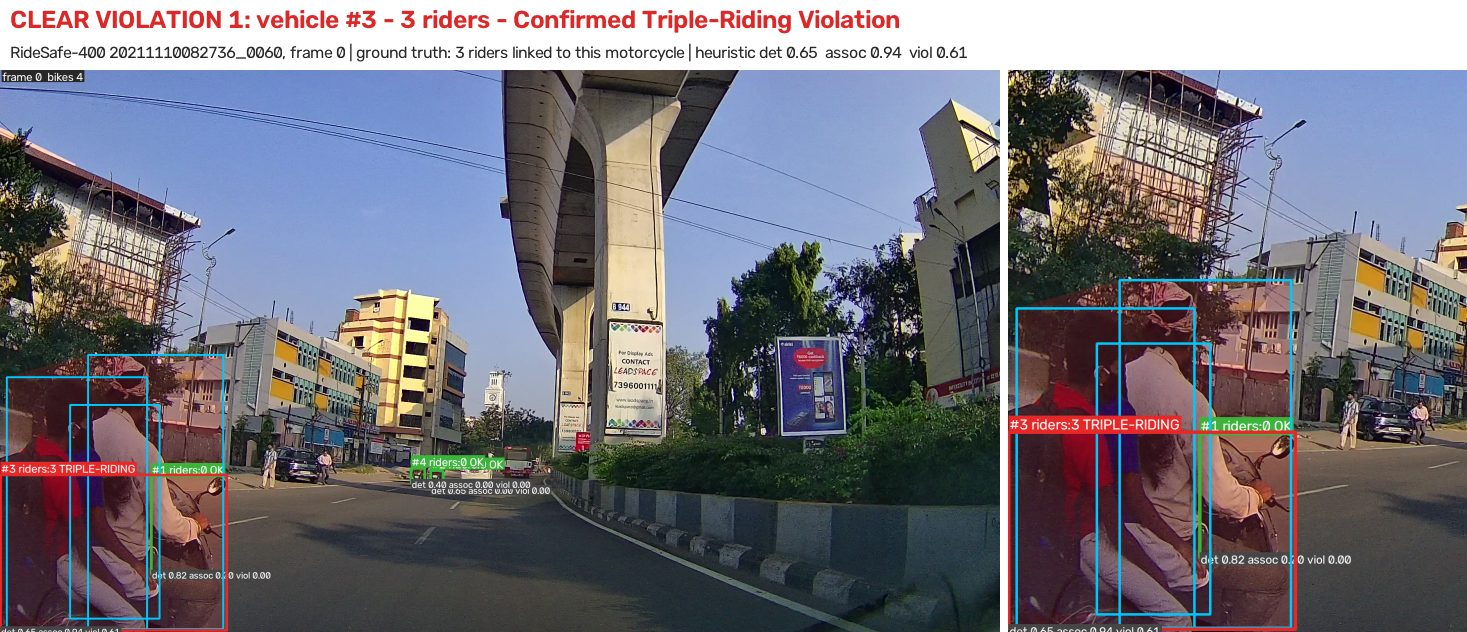

**Violation 2** — `20221017121145_0060`, frame 1350: ground truth **3** rider(s), predicted **3** -> *Confirmed Triple-Riding Violation* (heuristic det 0.92, assoc 0.81, viol 0.75)

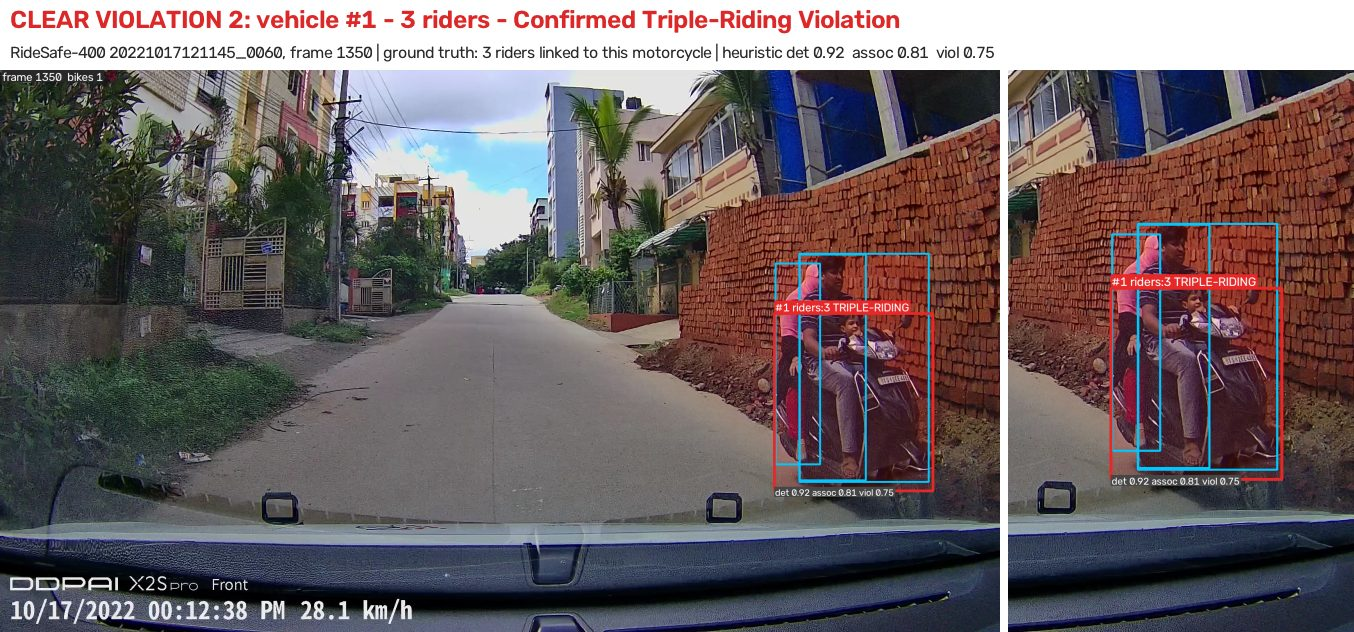

**Violation 3** — `20220819182838_0060`, frame 100: ground truth **3** rider(s), predicted **3** -> *Confirmed Triple-Riding Violation* (heuristic det 0.64, assoc 0.78, viol 0.50)

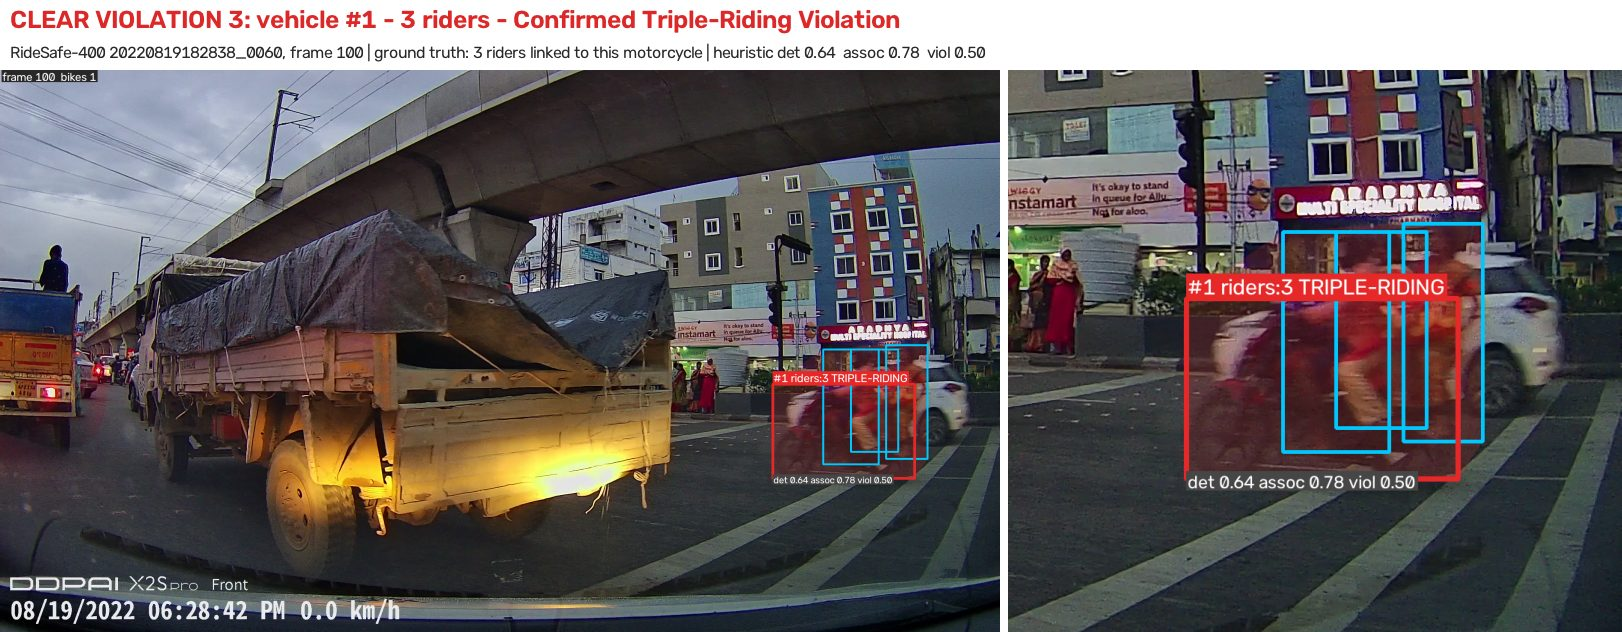

**Violation 4** — `20211109155059_0060`, frame 450: ground truth **3** rider(s), predicted **3** -> *Confirmed Triple-Riding Violation* (heuristic det 0.88, assoc 0.87, viol 0.76)

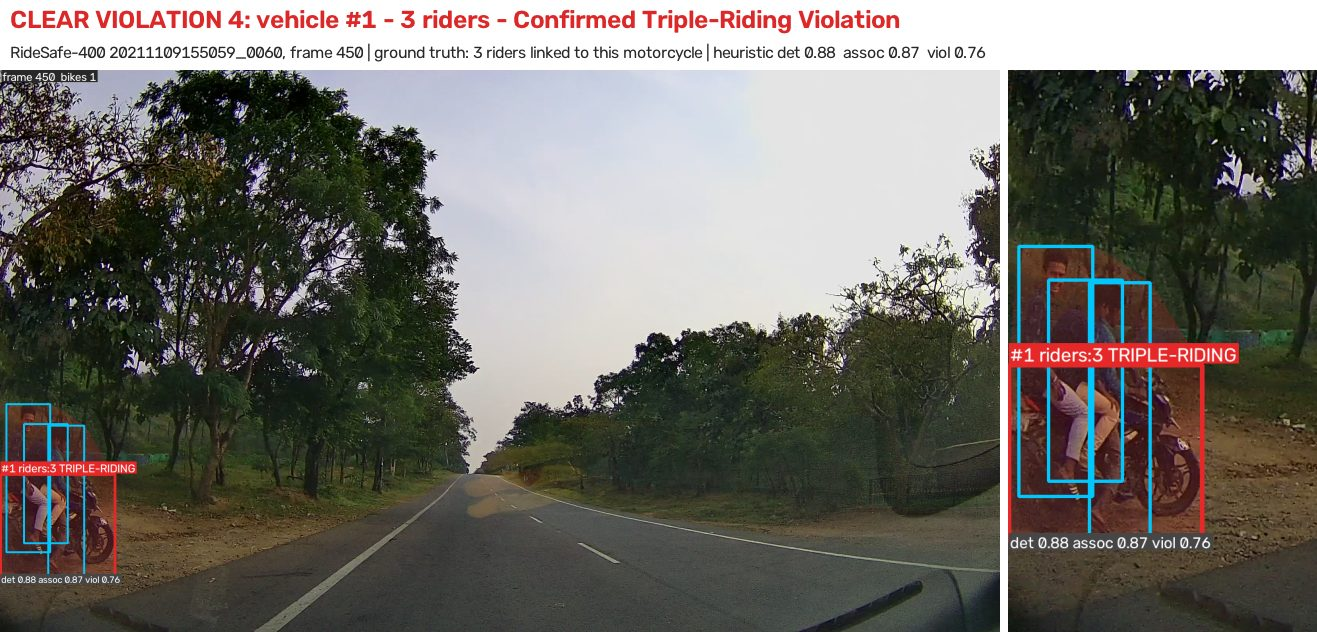

**Violation 5** — `20221010142708_0060`, frame 300: ground truth **3** rider(s), predicted **3** -> *Confirmed Triple-Riding Violation* (heuristic det 0.58, assoc 0.61, viol 0.36)

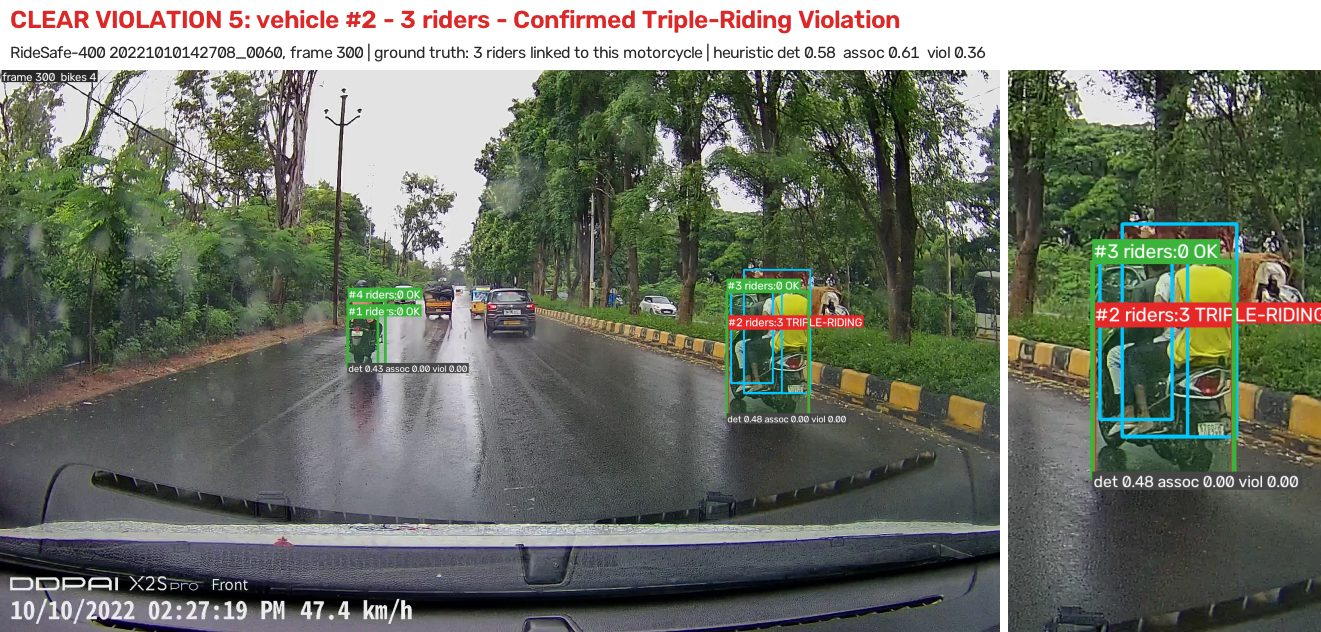


### Clear non-violations (1-2 riders)

**No Violation 1** — `20211125130614_0060`, frame 750: ground truth **2** rider(s), predicted **2** -> *No Violation* (heuristic det 0.86, assoc 1.00, viol 0.00)

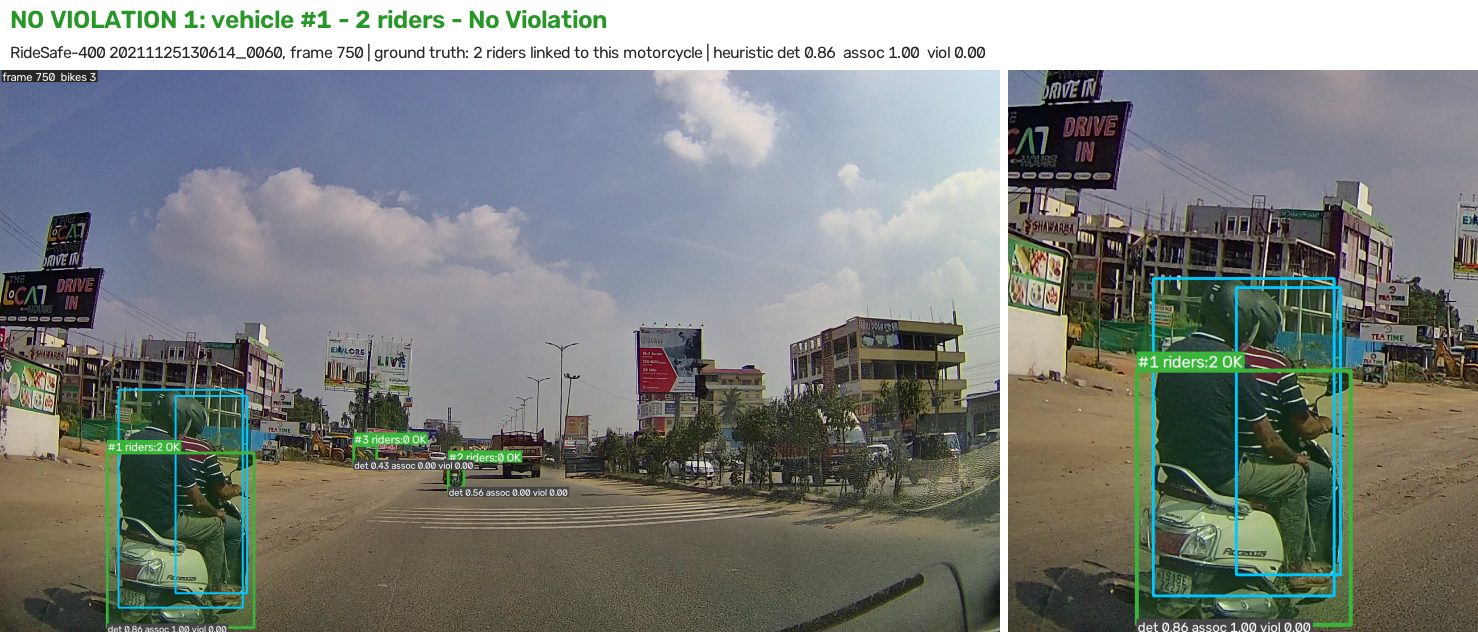

**No Violation 2** — `20211110124509_0060`, frame 25: ground truth **2** rider(s), predicted **2** -> *No Violation* (heuristic det 0.85, assoc 0.63, viol 0.00)

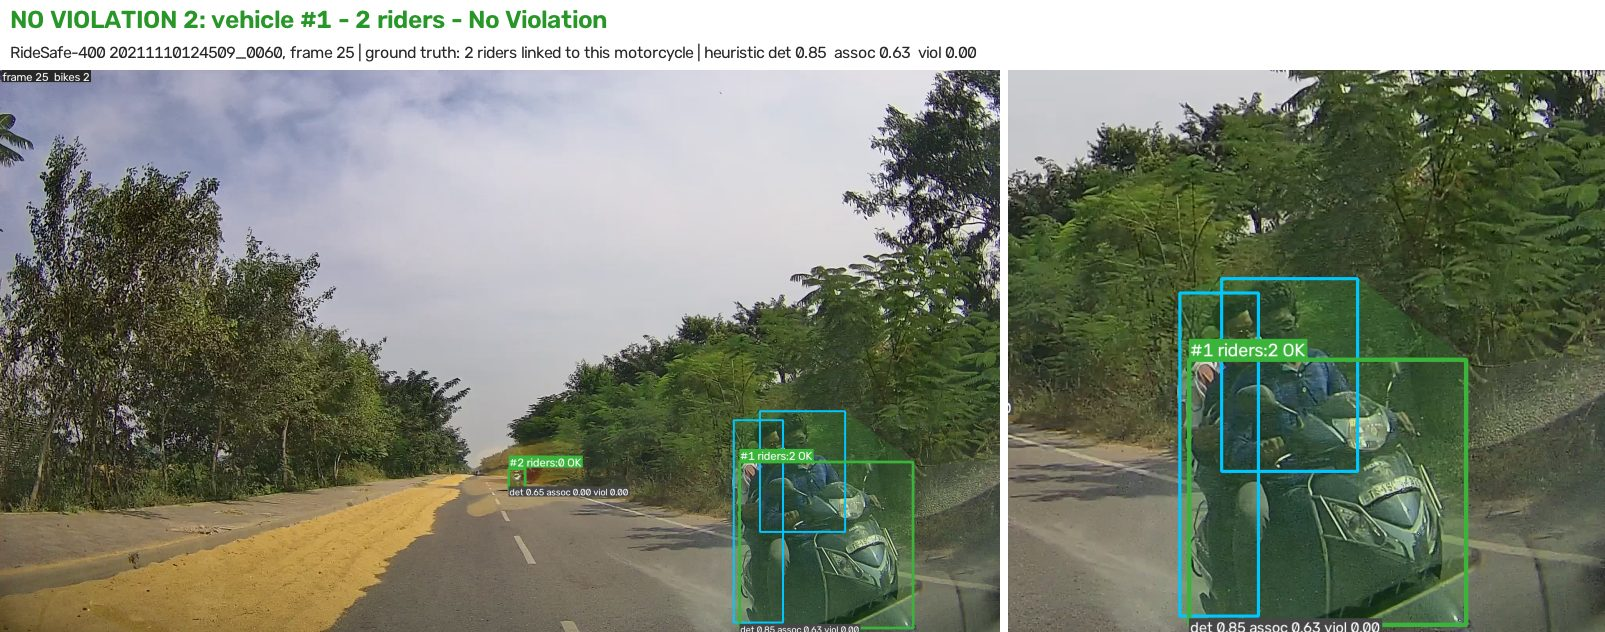

**No Violation 3** — `20220824144307_0060`, frame 875: ground truth **1** rider(s), predicted **1** -> *No Violation* (heuristic det 0.52, assoc 1.00, viol 0.00)

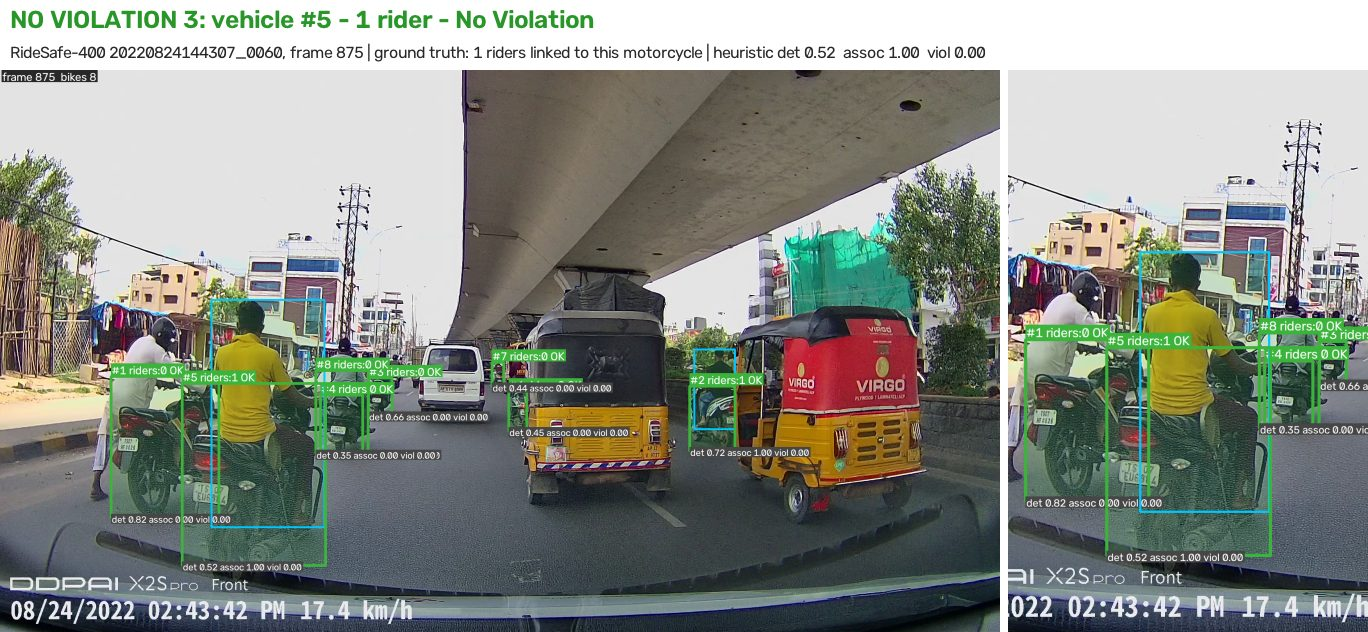

**No Violation 4** — `20221017121145_0060`, frame 225: ground truth **2** rider(s), predicted **2** -> *No Violation* (heuristic det 0.93, assoc 0.92, viol 0.00)

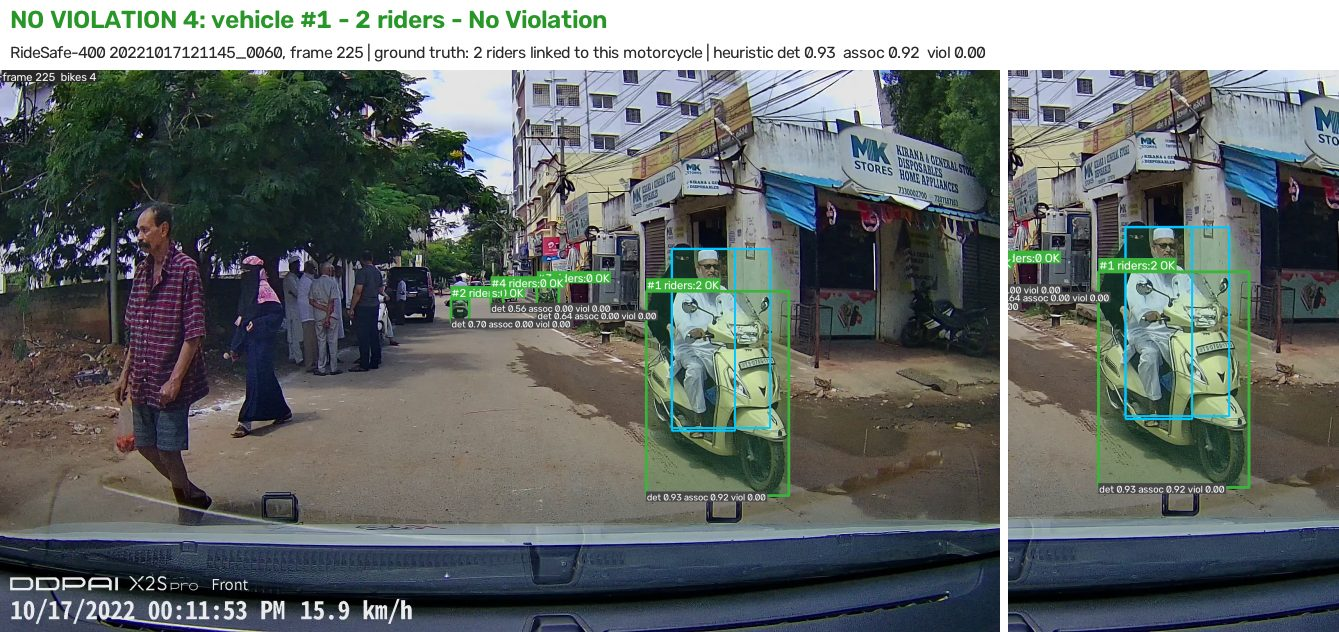

**No Violation 5** — `20221010121810_0060`, frame 1455: ground truth **1** rider(s), predicted **1** -> *No Violation* (heuristic det 0.83, assoc 0.49, viol 0.00)

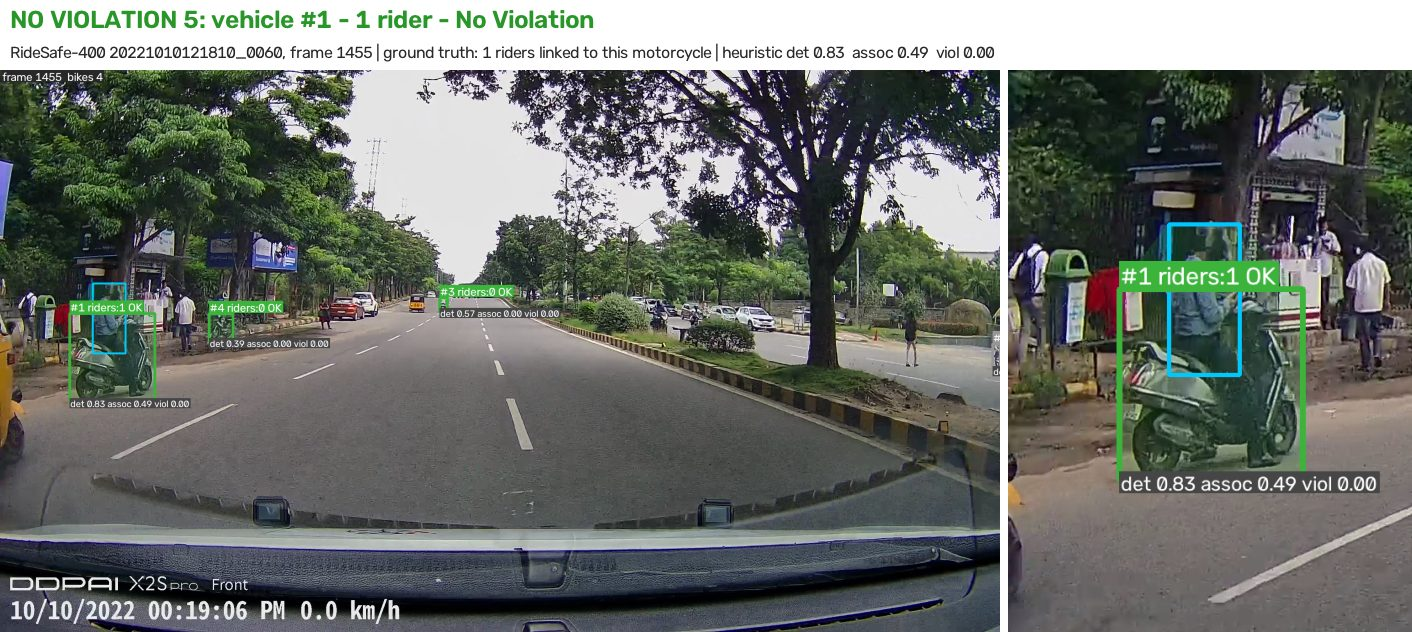


*Single-image mode:* *Confirmed* requires strict per-image conditions (association >= 0.6, detection >= 0.5, no ambiguous people); otherwise >= 3 riders is reported as *Potential*. In video, confirmation additionally needs >= 3 supporting frames (section 7).

## 16. Evaluation on RideSafe-400 ground truth
Runs the detectors **once per video** (cached), then evaluates **our pipeline** and the **naive expanded-box baseline** from the same detections. Set `EVAL_N_VIDEOS` (default 8; each video costs ~100 MB download + ~1-2 min on a T4). Sampling is seeded and **stratified to include videos with GT triple riding** (otherwise recall is unmeasurable) — so precision/recall are *not* estimates for natural traffic prevalence. With a handful of videos, expect wide uncertainty; the sample list is saved with the report.

**Honesty notes:** (1) no model is fine-tuned; (2) the evaluation videos are *not* used to set any threshold (defaults come from geometry reasoning; the optional tuning cell below uses a *different* seed offset); (3) GT triple labels come from `association_id` links and may omit riders left unlinked — see the ambiguous-GT column.

In [ ]:
EVAL_N_VIDEOS = 8
EVAL_FRAC_POSITIVE = 0.5
EVAL_SEED = CFG.seed + 100          # different seed from the oracle/demo samples

def match_counts(pred_boxes, gt_boxes, thr):
    m = hungarian_match(pred_boxes, gt_boxes, thr); tp = len(m)
    return tp, len(pred_boxes) - tp, len(gt_boxes) - tp

def run_evaluation(stems: List[str], cfg: Config, detector, token) -> dict:
    ours, naive = EvalAccumulator("ours", cfg), EvalAccumulator("naive", cfg)
    det_bike_preds, det_bike_gts = [], {}
    bike_op = collections.Counter(); person_recall = collections.Counter()
    trk = {k: [{}, {}] for k in ("bike", "rider")}          # [gt_tracks, pred_tracks] keyed by (stem, frame)
    veh_rows, vid_rows, per_video = [], [], []
    for stem in tqdm(stems, desc="evaluating videos"):
        try:
            paths = fetch_sample(cfg, INDEX, stem, token); gt = parse_cvat_xml(paths["xml"])
            run = process_video(paths["video"], cfg, detector, stem, gt, write_video=False, save_evidence=False, progress=False, write_outputs=False)
        except Exception as e:
            print(f"  skipping {stem}: {type(e).__name__}: {e}"); continue
        F = sorted(run["processed"] & set(gt.frames)); byf = {r.frame_idx: r for r in run["results"]}
        if not F:
            print(f"  {stem}: no overlap between processed frames and GT grid"); continue
        for f in F:
            det = run["dets"][f]
            ours.add_frame(stem, gt, f, pred_from_result(byf[f])); naive.add_frame(stem, gt, f, pred_naive(det, cfg))
            ours.n_frames += 1; ours.time_det += det.t_det; ours.time_pipe += byf[f].t_track_assoc
            gb = [b for _, b in gt.bikes.get(f, [])]; det_bike_gts[(stem, f)] = gb
            for b, c in zip(det.bike_xyxy, det.bike_conf):
                det_bike_preds.append(((stem, f), np.asarray(b), float(c)))
            keep = det.bike_conf >= cfg.bike_conf
            tp, fp, fn = match_counts(as_boxes(det.bike_xyxy)[keep], gb, cfg.eval_iou)
            bike_op["tp"] += tp; bike_op["fp"] += fp; bike_op["fn"] += fn
            grid = [r[2] for r in gt.riders.get(f, [])]; pk = det.person_conf >= cfg.person_conf
            tp, _, fn = match_counts(as_boxes(det.person_xyxy)[pk], grid, cfg.eval_iou); person_recall["tp"] += tp; person_recall["fn"] += fn
        ev = evaluate_tracks_and_vehicles(gt, run["results"], run["pipe"], set(F), cfg)
        bs, rs, gbs, grs = ev["seq"]
        for f in F:
            trk["bike"][0][(stem, f)] = gbs.get(f, []); trk["bike"][1][(stem, f)] = bs.get(f, [])
            trk["rider"][0][(stem, f)] = grs.get(f, []); trk["rider"][1][(stem, f)] = rs.get(f, [])
        for r in ev["rows"]: r["video"] = stem
        veh_rows += ev["rows"]; vid_rows.append(dict(video=stem, **ev["video"]))
        per_video.append(dict(video=stem, frames_evaluated=len(F), gt_triple_bikes=len(gt.triple_bikes(cfg.gt_min_frames)),
                              pred_confirmed=sum(1 for r in run["pipe"].vehicle_summary() if r["final_status"] == ST_CONF)))
    out = dict(ours=ours.report(), naive=naive.report(), per_video=per_video)
    ap = lambda t: float(np.nanmean([average_precision(det_bike_preds, det_bike_gts, t)]))
    out["detection_motorcycle"] = dict(AP50=ap(0.5), AP50_95=float(np.nanmean([average_precision(det_bike_preds, det_bike_gts, t) for t in np.arange(0.5, 0.96, 0.05)])),
                                       precision_at_op=bike_op["tp"] / max(bike_op["tp"] + bike_op["fp"], 1),
                                       recall_at_op=bike_op["tp"] / max(bike_op["tp"] + bike_op["fn"], 1), op_conf=cfg.bike_conf)
    out["detection_riders"] = dict(recall_any_person_box=person_recall["tp"] / max(person_recall["tp"] + person_recall["fn"], 1),
                                   assigned_rider_precision=out["ours"]["association"]["rider_precision_at_iou"],
                                   assigned_rider_recall=out["ours"]["association"]["rider_recall_at_iou"],
                                   note="No rider AP is reported: the person detector also fires on un-annotated pedestrians.")
    out["tracking"] = {k: idf1_idsw(*v, cfg.eval_iou) for k, v in trk.items()}
    out["vehicle_level"] = _binary_metrics([(r["gt_positive"], r["pred_positive"]) for r in veh_rows]) if veh_rows else {}
    out["video_level"] = _binary_metrics([(r["gt_positive"], r["pred_positive"]) for r in vid_rows]) if vid_rows else {}
    matched = [r for r in veh_rows if r["matched"]]
    if matched:
        rel, brier, ece = reliability_table([r["score"] for r in matched], [r["gt_positive"] for r in matched])
        out["calibration_of_heuristic_score"] = dict(n=len(matched), reliability=rel, brier=brier, ece=ece,
                                                     note="Heuristic violation_score is NOT a calibrated probability; compare mean_score vs observed rate.")
        if len(matched) >= 30 and len({r["gt_positive"] for r in matched}) == 2:       # leave-one-video-out isotonic
            cal = []
            for v in {r["video"] for r in matched}:
                tr_ = [r for r in matched if r["video"] != v]; te_ = [r for r in matched if r["video"] == v]
                if len({r["gt_positive"] for r in tr_}) == 2:
                    ic = IsotonicCalibrator().fit([r["score"] for r in tr_], [r["gt_positive"] for r in tr_])
                    cal += list(zip(ic.predict([r["score"] for r in te_]), [r["gt_positive"] for r in te_]))
            if cal:
                out["calibration_of_heuristic_score"]["calibrated_prob_brier_leave_one_video_out"] = float(np.mean([(p - y) ** 2 for p, y in cal]))
        else:
            out["calibration_of_heuristic_score"]["calibrator"] = "not fitted (needs >= 30 matched vehicles with both classes)"
    out["vehicle_rows"] = veh_rows; out["video_rows"] = vid_rows
    return out

EVAL = None
if INDEX and DETECTOR is not None and EVAL_N_VIDEOS > 0:
    EVAL_STEMS, EVAL_INFO = sample_stratified(CFG, INDEX, EVAL_N_VIDEOS, EVAL_SEED, HF_TOKEN, EVAL_FRAC_POSITIVE, probe=60)
    print("Evaluation videos:", EVAL_STEMS, "\nsampling:", EVAL_INFO)
    EVAL = run_evaluation(EVAL_STEMS, CFG, DETECTOR, HF_TOKEN)
else:
    print("Evaluation skipped (need dataset access + loaded detector).")

### Evaluation report

In [ ]:
def _fmt(x):
    return "n/a" if (x is None or (isinstance(x, float) and x != x)) else (f"{x:.3f}" if isinstance(x, float) else str(x))

if EVAL:
    o, n = EVAL["ours"], EVAL["naive"]
    print("=== Motorcycle detection (pretrained YOLO11, no fine-tuning) ===")
    print(pd.Series(EVAL["detection_motorcycle"]).map(_fmt).to_string())
    print("\n=== Rider detection ===");  print(pd.Series({k: v for k, v in EVAL["detection_riders"].items() if k != "note"}).map(_fmt).to_string()); print(EVAL["detection_riders"]["note"])
    rows = {}
    for name, r in (("ours", o), ("naive baseline", n)):
        a, t, c = r["association"], r["triple_frame_level"], r.get("rider_count", {})
        rows[name] = {"assoc accuracy (matched riders)": a["accuracy_among_matched_riders"], "assoc recall (linkable GT riders)": a["recall_of_linkable_gt_riders"],
                      "wrong-bike rate": a["false_assoc_rate_wrong_bike"], "assigned w/o GT rider (upper bound on pedestrian FA)": a["false_assoc_rate_no_gt_rider_upper_bound"],
                      "combined false-association (upper bound)": a["false_assoc_rate_combined_upper_bound"],
                      "count exact-match": c.get("exact_match"), "count over-count rate": c.get("over_count_rate"), "count over by >=2": c.get("over_count_by_2plus_rate"),
                      "max riders on a bike": max(map(int, r["max_riders_histogram"])) if r["max_riders_histogram"] else None,
                      "triple P (strict)": t["precision"], "triple P (excl. ambiguous GT)": t["precision_excluding_ambiguous_gt"], "triple R": t["recall"], "triple F1": t["F1"],
                      "TP/FP/FN/TN": f"{t['TP']}/{t['FP']}/{t['FN']}/{t['TN']}"}
    print("\n=== Association, rider count and frame-level triple riding ==="); print(pd.DataFrame(rows).map(_fmt).to_string())
    print("\n=== Riders-per-bike histogram (max predicted count per bike-frame) ===")
    print(pd.DataFrame({"ours": o["max_riders_histogram"], "naive": n["max_riders_histogram"]}).fillna(0).astype(int).to_string())
    print("\n=== Vehicle-level triple-riding (track final status == Confirmed vs GT) ==="); print(pd.Series({k: v for k, v in EVAL["vehicle_level"].items()}).map(_fmt).to_string())
    print("\n=== Video-level ===");  print(pd.Series({k: v for k, v in EVAL["video_level"].items()}).map(_fmt).to_string())
    print("\n=== Tracking (IoU>=0.5; sampled frames only) ===");  print(pd.DataFrame(EVAL["tracking"]).map(_fmt).to_string())
    print("\n=== Speed ===");  print(pd.Series(o["timing"]).map(_fmt).to_string())
    cal = EVAL.get("calibration_of_heuristic_score")
    if cal:
        print(f"\n=== Is the heuristic violation_score a probability? n={cal['n']}  Brier={_fmt(cal['brier'])}  ECE={_fmt(cal['ece'])} ===")
        print(pd.DataFrame(cal["reliability"]).to_string(index=False)); print({k: v for k, v in cal.items() if k.startswith("calibrat")})
    # confusion matrices
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
    for a_, (ttl, cm) in zip(ax, [("Ours: frame level", o["triple_frame_level"]["confusion_matrix"]),
                                  ("Naive: frame level", n["triple_frame_level"]["confusion_matrix"]),
                                  ("Ours: vehicle level", EVAL["vehicle_level"].get("confusion_matrix", [[0, 0], [0, 0]]))]):
        a_.imshow(np.array(cm), cmap="Blues"); a_.set_xticks([0, 1], ["pred no", "pred triple"]); a_.set_yticks([0, 1], ["GT no", "GT triple"]); a_.set_title(ttl)
        for i in range(2):
            for j in range(2): a_.text(j, i, cm[i][j], ha="center", va="center", color="black", fontsize=12)
    plt.tight_layout(); plt.savefig(DIRS["eval"] / "confusion_matrices.png", dpi=120); plt.show()
    (DIRS["eval"] / "evaluation.json").write_text(json.dumps({k: v for k, v in EVAL.items()}, indent=2, default=float))
    pd.DataFrame(EVAL["vehicle_rows"]).to_csv(DIRS["eval"] / "vehicle_level_rows.csv", index=False)
    print("\nSaved:", DIRS["eval"])

### Optional: tune association thresholds on *separate* videos
Re-runs only tracking + association from cached detections, so it is cheap. Uses a **different seed offset** and excludes the evaluation videos. The objective (`recall of linkable riders - 2 x combined false-association upper bound`) is my arbitrary choice; inspect the whole grid before adopting a setting, and **re-run the evaluation after changing `CFG`**. Disabled by default (`TUNE_N_VIDEOS = 0`).

In [ ]:
TUNE_N_VIDEOS = 0
def tune_association(stems, base_cfg: Config, grid: Dict[str, Sequence[float]]) -> pd.DataFrame:
    data = []
    for stem in stems:
        paths = fetch_sample(base_cfg, INDEX, stem, HF_TOKEN, with_video=False); gt = parse_cvat_xml(paths["xml"])
        dets = load_cache(stem, base_cfg)
        if dets:
            data.append((stem, gt, dets))
    rows = []
    for vals in itertools.product(*grid.values()):
        cfg = dataclasses.replace(base_cfg, **dict(zip(grid.keys(), vals)))
        acc = EvalAccumulator("tune", cfg)
        for stem, gt, dets in data:
            frames = sorted(set(dets) & set(gt.frames)); _, res = rerun_from_cache(dets, cfg, sorted(dets))
            byf = {r.frame_idx: r for r in res}
            for f in frames: acc.add_frame(stem, gt, f, pred_from_result(byf[f]))
        r = acc.report(); a = r["association"]
        rows.append(dict(zip(grid.keys(), vals), assoc_recall=a["recall_of_linkable_gt_riders"], wrong_bike=a["false_assoc_rate_wrong_bike"],
                         combined_FA_ub=a["false_assoc_rate_combined_upper_bound"], triple_F1=r["triple_frame_level"]["F1"],
                         objective=a["recall_of_linkable_gt_riders"] - 2 * a["false_assoc_rate_combined_upper_bound"]))
    return pd.DataFrame(rows).sort_values("objective", ascending=False)

if TUNE_N_VIDEOS and INDEX and DETECTOR is not None:
    TUNE_STEMS, _ = sample_stratified(CFG, INDEX, TUNE_N_VIDEOS, CFG.seed + 999, HF_TOKEN, 0.5, probe=80)
    TUNE_STEMS = [s for s in TUNE_STEMS if s not in set(EVAL_STEMS if EVAL else [])]
    for s in TUNE_STEMS:           # make sure detections are cached
        paths = fetch_sample(CFG, INDEX, s, HF_TOKEN); process_video(paths["video"], CFG, DETECTOR, s, parse_cvat_xml(paths["xml"]), write_video=False, save_evidence=False, progress=False, write_outputs=False)
    TUNE_TABLE = tune_association(TUNE_STEMS, CFG, dict(tau_assign=[0.35, 0.45, 0.55], ambiguity_margin=[0.05, 0.08, 0.15]))
    print(TUNE_TABLE.to_string(index=False))

## 17. Export
Zips everything under the output directory (annotated media, evidence, reports, evaluation) for download.

In [ ]:
def export_outputs(cfg: Config, name="triple_riding_outputs") -> Path:
    root = Path(cfg.out_dir); target = root.parent / f"{name}.zip"
    skip = {"cache", "samples"}                           # large / re-creatable
    with zipfile.ZipFile(target, "w", zipfile.ZIP_DEFLATED) as z:
        for p in root.rglob("*"):
            if p.is_file() and not (set(p.relative_to(root).parts) & skip):
                z.write(p, p.relative_to(root))
    print(f"Wrote {target} ({target.stat().st_size / 2**20:.1f} MB)")
    return target

EXPORT = export_outputs(CFG)
if IN_COLAB:
    try:
        from google.colab import files; files.download(str(EXPORT))
    except Exception as e:
        print("Download manually from the file browser:", EXPORT)

## 18. Limitations (please read)

**What the author did and did not run.** On CPU, before delivery: the synthetic tests (section 13); the GT-oracle check on real RideSafe XMLs (section 14); and a small plumbing run with real `yolo11n` models over 3 real RideSafe videos through every stage including evaluation and export (that tiny CPU configuration reached only ~0.22 motorcycle recall, so its metrics are not representative); plate detector loading and EasyOCR on a rendered plate image. **Not run by the author:** a Colab GPU session with the default `yolo11l` @1280 configuration, a meaningful-size evaluation, and plate reading on real dashcam footage. Treat the numbers you generate in sections 15-16 as the real results, and expect the first Colab run might need small fixes (e.g. Ultralytics API changes).

**Methodology**
* Pretrained COCO detectors only. COCO "motorcycle" includes scooters/mopeds; riders of bicycles, e-rickshaws, and three-wheelers are not handled. Small/far motorcycles (common in dashcam footage) are the dominant failure mode.
* Association thresholds are **uncalibrated heuristics** from geometric reasoning. They assume a roughly rear/front/side dashcam view with a ground plane; extreme camera angles, very wide bike boxes, or boxes that include riders may need re-tuning (tuning cell provided).
* Pose cues (hips, "seated" posture) need confident keypoints; heavily occluded riders fall back to box geometry and are less reliable. A rider hidden behind two others may simply never be detected: the system reports *Potential* when ambiguous people exist, but cannot count what it cannot see. A pedestrian standing very close to a bike at the same depth can still be mis-associated.
* Compared with Goyal et al. (2022) this notebook has **no learned trapezium regressor, no amodal box completion and no curriculum-trained rider/motorcycle detector**. Those are the natural upgrades; RideSafe-400's rider/motorcycle boxes + association IDs (and its polyline annotations) provide the training signal.
* Tracker: own compact ByteTrack-style implementation, **no camera-motion compensation or appearance ReID** (BoT-SORT-style CMC would help with dashcam ego-motion). Short tracks (< `trk_min_hits` frames) are never reported; in video the first frame of a new object produces no output yet.
* Temporal rule parameters (window, k, ratio) are design choices, not fitted. Fast-passing bikes visible for < ~3 processed frames end as *Insufficient Visual Evidence* or *Potential*.
* `violation_score`, `assoc_conf`, `det_conf` are **heuristic**. Calibration is only attempted from evaluation data and is meaningful only with many vehicles.

**Evaluation**
* RideSafe has no official split file in the repo; samples are seeded random, stratified to include GT-positive videos, so precision/recall do not reflect natural prevalence. A few videos give wide confidence intervals; **no confidence intervals are computed**.
* GT quirks found while inspecting the data: annotation grid step is 5 for most videos but 1 for some; the annotated window is 300 frames; riders with `association_id = -1` are sometimes plausibly real riders of an annotated motorcycle (hence the strict vs. "excluding ambiguous GT" precision); pedestrians are not annotated, so the *no-GT-rider* component of false association is an upper bound.
* Tracking metrics are on the sampled (strided) frames, with GT motorcycle identity taken from `motor_track_id`.
* Plate recognition is not evaluated; the default plate detector is not India-specific, and plates are often unreadable at dashcam range.

**Licences:** RideSafe-400 is CC BY-NC-SA (non-commercial). Ultralytics YOLO11 and the default plate detector are AGPL-3.0. EasyOCR is Apache-2.0.

## 19. References
1. Goyal, A., Agarwal, D., et al. (IIIT Hyderabad). *Detecting, Tracking and Counting Motorcycle Rider Traffic Violations on Unconstrained Roads.* CVPR Workshops (UG2+) 2022. — trapezium instance boxes, curriculum-learned rider/motorcycle detector, amodal regressor.
2. Zhang, Y. et al. *ByteTrack: Multi-Object Tracking by Associating Every Detection Box.* ECCV 2022.
3. Aharon, N., Orfaig, R., Bobrovsky, B.-Z. *BoT-SORT: Robust Associations Multi-Pedestrian Tracking.* arXiv 2206.14651, 2022.
4. Bewley, A. et al. *Simple Online and Realtime Tracking (SORT).* ICIP 2016; Wojke, N. et al. *DeepSORT.* ICIP 2017; Cao, J. et al. *OC-SORT.* CVPR 2023.
5. Jocher, G., Qiu, J. *Ultralytics YOLO11.* 2024 (software). Lin, T.-Y. et al. *Microsoft COCO.* ECCV 2014.
6. Ristani, E. et al. *Performance Measures and a Data Set for Multi-Target, Multi-Camera Tracking* (IDF1). ECCVW 2016.
7. Kuhn, H. W. *The Hungarian method for the assignment problem.* 1955.
8. RideSafe-400 dataset card, `huggingface.co/datasets/DeepBug/RideSafe-400` (IIIT-Hyderabad).